# Tổng hợp phát hiện EDA — 60 cổ phiếu HOSE thuộc 10 ngành

Notebook này gom **những phát hiện đắt giá nhất** từ bốn notebook EDA chi tiết (`01`–`04`) thành một mạch đọc liền, cho **60 mã** nhóm theo ngành:
ngân hàng (10 mã), bất động sản (14), tiêu dùng (10), năng lượng (8), thép (3), hoá chất (3), công nghiệp (5), công nghệ (1), chứng khoán (5), nông nghiệp (1).
Gồm 20 mã vốn hoá lớn của giai đoạn trước và 40 mã bổ sung chọn bằng tiêu chí dữ liệu (`src/download_extended.py`); hai nhóm được đối chiếu ở Phát hiện 10.
Mỗi phát hiện gồm: **(1)** ô giải thích — tính gì, công thức, ý nghĩa ký hiệu, các bước; **(2)** ô code; **(3)** hình;
**(4)** phần phân tích ngắn ngay sau hình.

| # | Phát hiện | Hệ quả cho mô hình |
|---|---|---|
| 1 | Dữ liệu VHM trước niêm yết là giá ảo; TCB niêm yết sau mốc đầu khung → khung phân tích chung từ 01/06/2018 | Mọi thống kê dùng chung một khung (T = 2.103 phiên chung đủ 60 mã) |
| 2 | Rủi ro – lợi suất rất khác nhau giữa các mã và các ngành | NVL, PNJ lỗ và sụt giảm sâu; ngành quyết định phần lớn khác biệt |
| 3 | Lợi suất đuôi dày, không chuẩn ở cả 60 mã | Không dùng giả định chuẩn |
| 4 | Biên độ ±7% **chặn** đuôi phân phối; ở 54/60 mã toàn bộ 14 phiên cực trị (lợi suất thô) nằm đúng tại biên | Ước lượng đuôi kiểu Hill không dùng được; cần lọc GARCH và phương pháp dựa trên hạng |
| 5 | Biến động cụm mạnh ở cả 60 mã, các đợt biến động cao trùng nhau giữa các ngành | Lọc GARCH trước khi phân tích phụ thuộc |
| 6 | Một nhân tố thị trường chung (37,5% phương sai) + nhiều nhân tố ngành hẹp (chứng khoán, thép, phân bón, Vingroup) | Kiểm soát nhân tố chung và nhân tố ngành khi tìm quan hệ nhân quả |
| 7 | Phụ thuộc đuôi dưới mạnh hơn Gaussian ở 1.770/1.770 cặp (1.746 cặp có CI loại trừ 0) | Cần copula/mô hình đuôi, không chỉ tương quan |
| 8 | Không cặp nào trong 3.540 cặp dẫn–trễ vượt hiệu chỉnh Bonferroni/Holm | Quan hệ chủ yếu là đồng thời |
| 9 | Khối lượng tăng → biến động tăng ở cả 60 mã | Khối lượng là biến giải thích tiềm năng cho biến động |
| 10 | Khác biệt theo ngành; 40 mã bổ sung biến động hơn, bị chặn biên gấp đôi 20 mã cũ | Diễn giải theo ngành; xử lý chặn biên đặc biệt quan trọng với mã nhỏ |

**Ký hiệu chung.** $P_{i,t}$: giá đóng cửa (nghìn đồng, đã điều chỉnh) của mã $i$ ở phiên $t$;
lợi suất log $r_{i,t} = \ln(P_{i,t}/P_{i,t-1})$; $T$: số phiên trong khung phân tích; năm có 252 phiên giao dịch.

**Chạy trước:** `python src/build_database.py` (dựng `data/interim/stocks.duckdb`). Hình được lưu thêm vào `report/figure/eda/finding_*.png|pdf`.

## 0. Thiết lập

**Ô này làm gì:** tìm thư mục gốc đồ án, nạp module dùng chung `src/eda_utils.py` (kết nối DuckDB, bảng màu, style hình
theo chuẩn công bố), mở CSDL ở chế độ chỉ đọc và lấy ma trận lợi suất log dạng rộng `r` (mỗi cột một mã) từ view
`v_returns_wide` — view này đã giới hạn sẵn trong khung phân tích chung và bỏ các phiên không có lợi suất.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from scipy.stats import rankdata
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE

r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
start, end = con.execute("SELECT analysis_start, analysis_end FROM analysis_config").fetchone()

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

SC = {**SC, "Công nghệ": PAL["teal"]}      # tách màu Công nghệ khỏi Tiêu dùng (cùng họ xanh lá) khi tô theo ngành
ORIG = U.ORIGINAL_SYMBOLS
iu = np.triu_indices(len(SYMBOLS), 1)
pairs = [(a, b) for k, a in enumerate(SYMBOLS) for b in SYMBOLS[k + 1:]]          # 1.770 cặp không có hướng
BASE = U.BASE_SYMBOLS                     # 20 mã của giai đoạn trước, đối chiếu với 40 mã bổ sung ở Phát hiện 10
pair_names = [f"{a}–{b}" for a, b in pairs]
same_sector = np.array([SECTOR[a] == SECTOR[b] for a, b in pairs])
print(f"Khung phân tích: {start} → {end} | T = {len(r)} phiên chung × {r.shape[1]} mã ({len(pairs)} cặp: {same_sector.sum()} cùng ngành, {(~same_sector).sum()} khác ngành)")

Khung phân tích: 2018-06-01 → 2026-11-25 | T = 2103 phiên chung × 60 mã (1770 cặp: 235 cùng ngành, 1535 khác ngành)


## Phát hiện 1 — Giá VHM trước niêm yết là giá ảo; chọn khung phân tích chung

**Tính gì:** với mỗi mã, đếm số phiên trước ngày niêm yết, số phiên khối lượng bằng 0, ngày có dữ liệu đầu tiên;
và lợi suất "ảo" sinh ra nếu tính lợi suất qua mốc niêm yết của VHM.

**Công thức.** Cờ niêm yết $\text{is\_listed}_{i,t} = \mathbb{1}[t \ge t_i^{\text{niêm yết}}]$ và cờ giao dịch
$\text{is\_traded}_{i,t} = \mathbb{1}[V_{i,t} > 0]$ ($V$: khối lượng). Lợi suất chỉ được tính khi phiên liền trước đã niêm yết:

$$r_{i,t} = \begin{cases}\ln(P_{i,t}/P_{i,t-1}) & \text{nếu } t-1 \ge t_i^{\text{niêm yết}}\\ \text{NULL} & \text{ngược lại}\end{cases}$$

**Các bước:** (1) đọc bảng `daily_features` (toàn bộ lịch sử, chưa cắt khung); (2) tổng hợp theo mã bằng SQL;
(3) tính riêng lợi suất qua mốc 16→17/05/2018 của VHM để thấy độ lớn sai số nếu không xử lý;
(4) vẽ dải thời gian có dữ liệu thật của từng mã, đánh dấu ngày bắt đầu khung phân tích.

Nếu không xử lý: lợi suất log VHM ngày 17/05/2018 = ln(30.99/8.41) = 1.30  (≈ 268% trong một phiên)


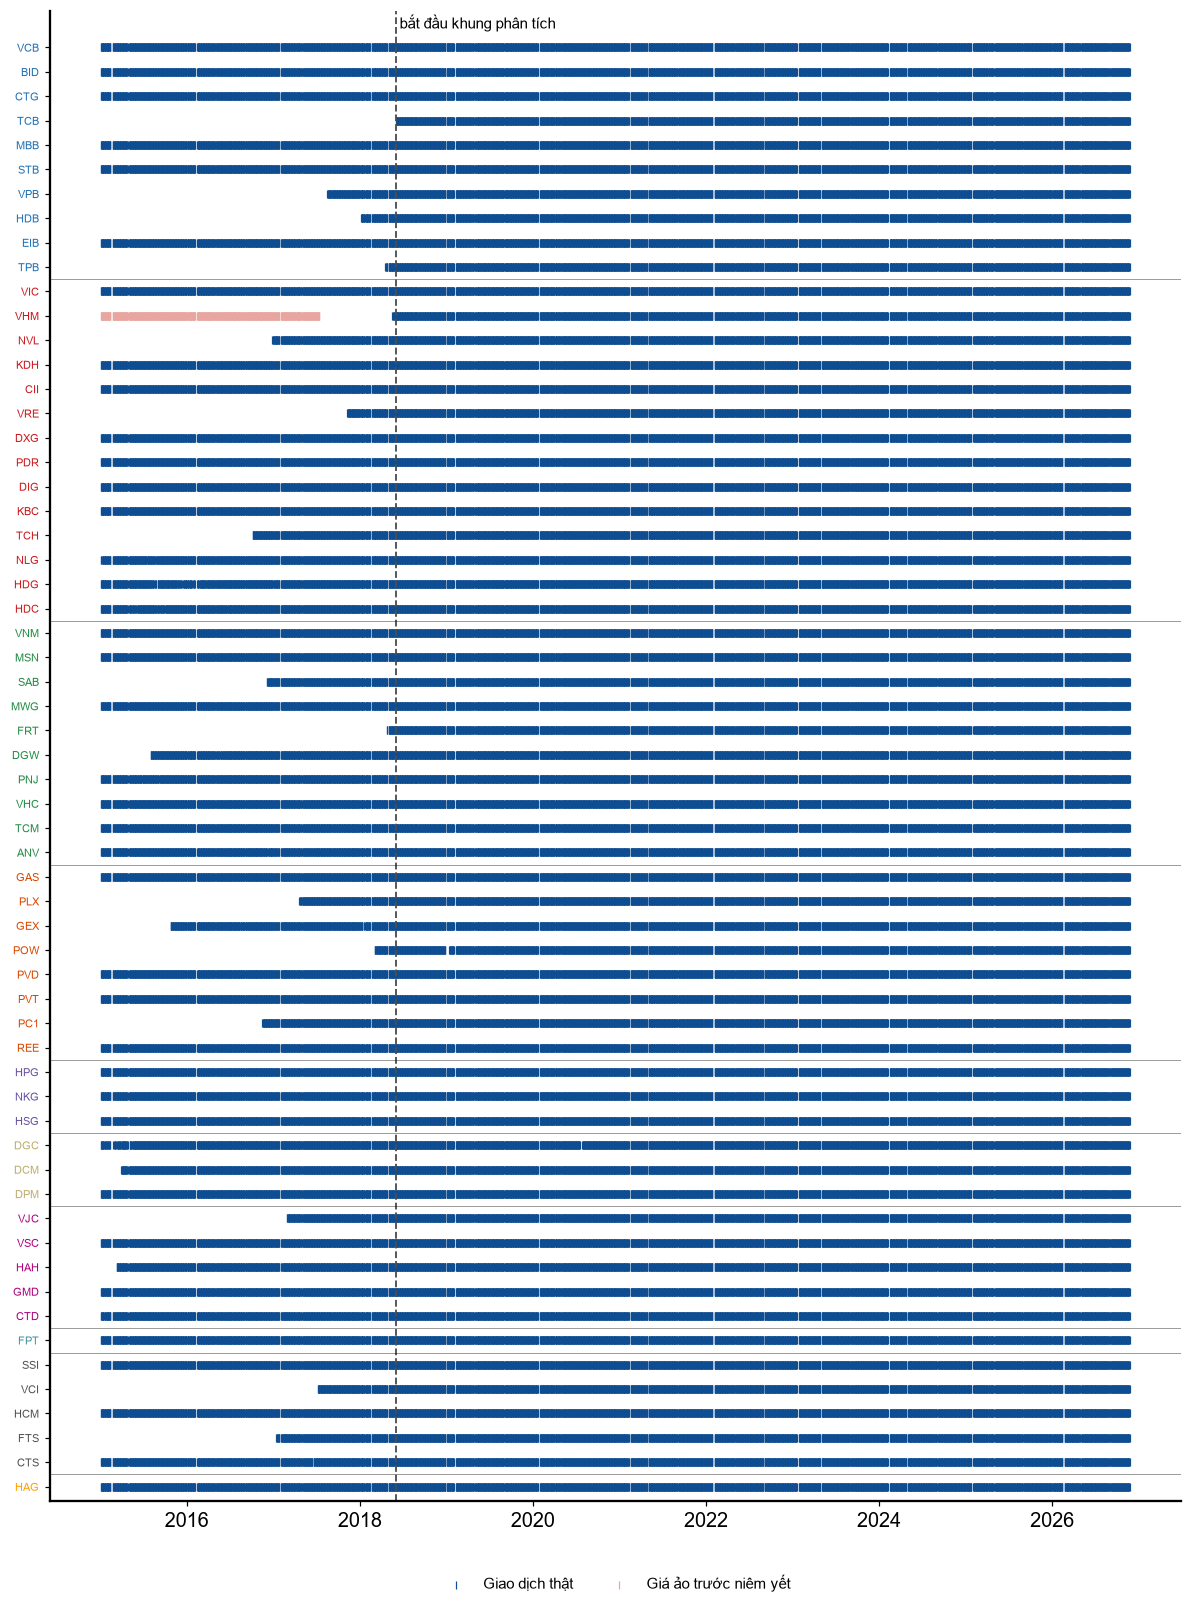

,ngành,ngay_dau_du_lieu,ngay_niem_yet,phien_chua_niem_yet,phien_KL_bang_0
symbol,,,,,
VCB,Ngân hàng,2015-01-05,2015-01-05,0,2
BID,Ngân hàng,2015-01-05,2015-01-05,0,2
CTG,Ngân hàng,2015-01-05,2015-01-05,0,2
TCB,Ngân hàng,2018-06-04,2018-06-04,0,0
MBB,Ngân hàng,2015-01-05,2015-01-05,0,2
STB,Ngân hàng,2015-01-05,2015-01-05,0,2
VPB,Ngân hàng,2017-08-17,2017-08-17,0,2
HDB,Ngân hàng,2018-01-05,2018-01-05,0,2
EIB,Ngân hàng,2015-01-05,2015-01-05,0,2


In [2]:
profile = con.execute("""
    SELECT f.symbol,
           MIN(f.time)                                   AS ngay_dau_du_lieu,
           MIN(f.time) FILTER (WHERE f.is_listed)        AS ngay_niem_yet,
           SUM((NOT f.is_listed)::INT)                   AS phien_chua_niem_yet,
           SUM((NOT f.is_traded)::INT)                   AS phien_KL_bang_0
    FROM daily_features f GROUP BY f.symbol""").df().set_index("symbol").loc[SYMBOLS].astype(
        {"phien_chua_niem_yet": int, "phien_KL_bang_0": int})
profile.insert(0, "ngành", [SECTOR[s] for s in profile.index])

p_before, p_after = con.execute("""
    SELECT LAG(close) OVER (ORDER BY time), close FROM ohlcv WHERE symbol = 'VHM'
    QUALIFY time = DATE '2018-05-17'""").fetchone()
print(f"Nếu không xử lý: lợi suất log VHM ngày 17/05/2018 = ln({p_after}/{p_before}) = {np.log(p_after/p_before):.2f}"
      f"  (≈ {np.exp(np.log(p_after/p_before))-1:.0%} trong một phiên)")

f = con.execute("SELECT symbol, time, is_listed, is_traded FROM daily_features").df()
fig, ax = plt.subplots(figsize=(11, 0.22 * len(SYMBOLS) + 1.5))
for y, s in enumerate(SYMBOLS):
    d = f[f.symbol == s]
    ok, fake = d[d.is_listed & d.is_traded], d[~d.is_listed]
    ax.scatter(ok.time, np.full(len(ok), y), marker="|", s=22, color=PAL["blue_main"], lw=0.8,
               label="Giao dịch thật" if y == 0 else None)
    ax.scatter(fake.time, np.full(len(fake), y), marker="|", s=22, color=PAL["red_2"], lw=0.8,
               label="Giá ảo trước niêm yết" if len(fake) else None)
ax.axvline(pd.Timestamp(start), color=PAL["gray_dark"], ls="--", lw=1.2)
ax.text(pd.Timestamp(start), -1.0, " bắt đầu khung phân tích", fontsize=10, va="center")
ax.set_yticks(range(len(SYMBOLS)), SYMBOLS, fontsize=7.5)
for t, s in zip(ax.get_yticklabels(), SYMBOLS): t.set_color(SC[SECTOR[s]])
for i in range(1, len(SYMBOLS)):
    if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: ax.axhline(i - 0.5, color="black", lw=0.5, alpha=0.5)
ax.set_ylim(len(SYMBOLS) - 0.4, -1.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=2, fontsize=10)
U.finalize_figure(fig, "finding_1_coverage"); plt.show()
profile

### Phân tích

- VHM có **629 phiên** (01/2015 → 16/05/2018) giá đứng yên 8,41 (578 phiên có khối lượng bằng 0) — không phải giao dịch thật trên HOSE. Nếu tính lợi suất qua mốc niêm yết, ta được lợi suất log **1,30 (≈ +268% trong một phiên)**.
- 59 mã còn lại không có phiên nào trước niêm yết trong dữ liệu; mã bắt đầu muộn nhất là **TCB 04/06/2018** (thiếu 2 phiên đầu khung), FRT 26/04/2018, TPB 19/04/2018, HDB 05/01/2018.
  POW (9 phiên đầu 2019) và DGC (6 phiên giữa 2020) không giao dịch trong khung — đúng thời điểm chuyển từ UPCoM/HNX lên HOSE.
  Dữ liệu nguồn có một lỗi giá đóng cửa bằng 0 (GEX 12/08/2016, ngoài khung) — loại khi nạp CSDL.
- **Quyết định:** khung chung **01/06/2018 → 25/11/2026**: 2.111–2.120 phiên cho mỗi mã và **T = 2.103 phiên chung** khi cần ma trận đủ 60 mã (tương quan, PCA, Granger, phụ thuộc đuôi).
  Lợi suất của phiên có phiên liền trước chưa niêm yết được đặt NULL ngay trong SQL nên không thể rò vào các phân tích sau.

## Phát hiện 2 — Rủi ro và lợi suất khác biệt lớn giữa các mã

**Tính gì:** lợi suất năm hoá, biến động năm hoá, tỷ số Sharpe và mức sụt giảm lớn nhất (max drawdown) của từng mã.

**Công thức.**

- Lợi suất trung bình năm hoá: $\hat\mu_i^{\text{năm}} = 252\cdot\bar r_i$, với $\bar r_i = \frac1T\sum_t r_{i,t}$ — vì lợi suất log cộng được theo thời gian.
- Biến động năm hoá: $\hat\sigma_i^{\text{năm}} = \sqrt{252}\cdot s_i$, với $s_i$ là độ lệch chuẩn mẫu của $r_{i,t}$ (giả định lợi suất ngày gần độc lập nên phương sai cộng theo số phiên).
- Sharpe (lãi suất phi rủi ro = 0): $SR_i = \hat\mu_i^{\text{năm}} / \hat\sigma_i^{\text{năm}}$ — lợi suất nhận được trên mỗi đơn vị rủi ro.
- Drawdown: với giá trị tài sản $W_{i,t} = \exp\big(\sum_{s\le t} r_{i,s}\big)$, $DD_{i,t} = W_{i,t}/\max_{s\le t}W_{i,s} - 1$; $MDD_i = \min_t DD_{i,t}$ — mức lỗ tệ nhất từ một đỉnh cũ.

**Các bước:** (1) tính bốn chỉ số trên `r`; (2) chuẩn hoá giá về 100 ở phiên đầu khung để so sánh trên cùng thang (log);
(3) vẽ bản đồ rủi ro – lợi suất cho 60 mã, kích thước điểm tỷ lệ với $|MDD|$, màu theo ngành.

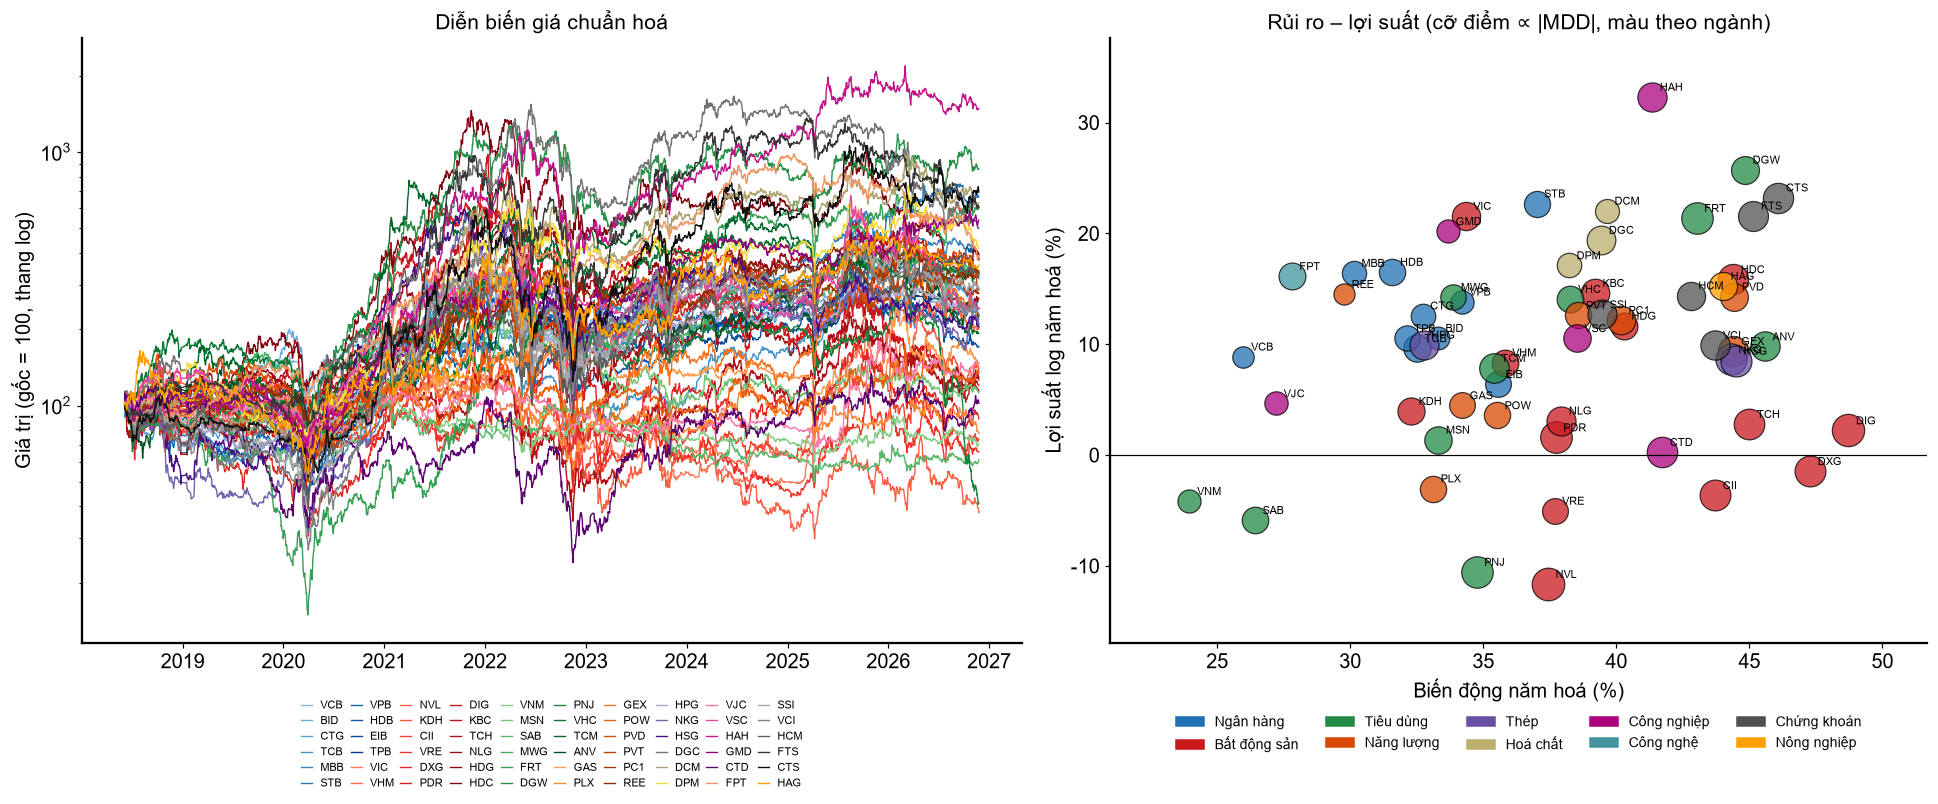

,ngành,mu_nam,sigma_nam,MDD,ngay_day,Sharpe
VCB,Ngân hàng,0.0888,0.2599,-0.3949,2020-03-23,0.3416
BID,Ngân hàng,0.1056,0.3329,-0.4450,2020-03-23,0.3171
CTG,Ngân hàng,0.1258,0.3272,-0.5187,2022-10-11,0.3846
TCB,Ngân hàng,0.0964,0.3250,-0.6434,2022-11-15,0.2964
MBB,Ngân hàng,0.1642,0.3013,-0.5064,2022-11-15,0.5450
STB,Ngân hàng,0.2269,0.3700,-0.5858,2022-10-24,0.6133
VPB,Ngân hàng,0.1384,0.3419,-0.4649,2020-03-31,0.4047
HDB,Ngân hàng,0.1652,0.3158,-0.5958,2020-03-30,0.5232
EIB,Ngân hàng,0.0639,0.3554,-0.5702,2022-11-21,0.1799
TPB,Ngân hàng,0.1053,0.3211,-0.5499,2022-10-11,0.3278


In [3]:
W = np.exp(r.cumsum())
dd = W / W.cummax() - 1
summary = pd.DataFrame({
    "ngành": [SECTOR[s] for s in SYMBOLS],
    "mu_nam": 252 * r.mean(),
    "sigma_nam": np.sqrt(252) * r.std(),
    "MDD": dd.min(),
    "ngay_day": dd.idxmin().dt.date,
}, index=SYMBOLS)
summary["Sharpe"] = summary.mu_nam / summary.sigma_nam

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})
for s in SYMBOLS:
    axes[0].plot(W.index, 100 * W[s], color=COL[s], lw=0.9, label=s)
axes[0].set_yscale("log"); axes[0].set_ylabel("Giá trị (gốc = 100, thang log)")
axes[0].set_title("Diễn biến giá chuẩn hoá")
axes[0].legend(ncol=10, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.08), columnspacing=0.6, handlelength=1.0)
for s in SYMBOLS:
    row = summary.loc[s]
    axes[1].scatter(100 * row.sigma_nam, 100 * row.mu_nam, s=500 * abs(row.MDD), color=SC[SECTOR[s]],
                    alpha=0.75, edgecolor="black", lw=0.8)
    axes[1].annotate(s, (100 * row.sigma_nam, 100 * row.mu_nam), xytext=(5, 4), textcoords="offset points", fontsize=7.5)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("Biến động năm hoá (%)"); axes[1].set_ylabel("Lợi suất log năm hoá (%)")
axes[1].set_title("Rủi ro – lợi suất (cỡ điểm ∝ |MDD|, màu theo ngành)")
axes[1].margins(0.12)
sector_legend(axes[1], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5, fontsize=9)
U.finalize_figure(fig, "finding_2_risk_return"); plt.show()
summary

### Phân tích

- **Lợi suất:** cao nhất ở **HAH (+32,3%/năm, Sharpe 0,78)**, DGW (+25,7%), CTS (+23,2%), STB (+22,7%, Sharpe 0,61). Âm ở **NVL (−11,6%/năm)**, PNJ (−10,5%), SAB (−5,9%), VRE (−5,0%).
  NVL có sụt giảm sâu nhất, **−91,2%** (đáy 09/04/2025), tiếp theo DIG (−89,7%), PDR (−86,1%), FRT (−85,2%, đáy COVID 30/03/2020), PNJ (−85,1%, đáy 23/11/2026, đang giảm ở cuối mẫu).
- **Biến động năm hoá 24–49%**: thấp nhất VNM (24,0%), VCB (26,0%), SAB (26,4%); cao nhất DIG (48,7%), DXG (47,3%), CTS (46,1%). Mã biến động cao không có lợi suất cao tương ứng (DXG, DIG lợi suất ≈ 0) →
  biến động không giải thích được chênh lệch lợi suất. MDD nhẹ nhất ở REE (−38,6%), VCB (−39,5%), BID (−44,5%) — hai ngân hàng quốc doanh đáy cùng ngày 23/03/2020.
- Nhiều mã chạm đáy cùng các đợt (15/11/2022 — 18 mã; cuối 03/2020; 09/04/2025) → gợi ý nhân tố chung (Phát hiện 6).

## Phát hiện 3 — Lợi suất đuôi dày, không tuân theo phân phối chuẩn

**Tính gì:** độ nhọn vượt chuẩn, kiểm định Jarque–Bera, bậc tự do của phân phối Student-t khớp với dữ liệu, tỷ lệ phiên
đứng giá; và so sánh mật độ thực nghiệm với chuẩn và Student-t trên **thang log** (để nhìn rõ phần đuôi).

**Công thức.**

- Độ lệch $S = \frac{1}{T}\sum_t z_t^3$, độ nhọn vượt chuẩn $K = \frac{1}{T}\sum_t z_t^4 - 3$ với $z_t = (r_t-\bar r)/s$. Phân phối chuẩn có $S = 0, K = 0$; $K > 0$ nghĩa là đỉnh nhọn hơn và đuôi dày hơn chuẩn.
- Jarque–Bera: $JB = \frac{T}{6}\left(S^2 + \frac{K^2}{4}\right) \sim \chi^2_2$ dưới giả thuyết $H_0$: phân phối chuẩn. $JB$ lớn → bác bỏ tính chuẩn.
- Student-t vị trí–thang đo: $f(x) = \frac{\Gamma(\frac{\nu+1}{2})}{\Gamma(\frac{\nu}{2})\sqrt{\nu\pi}\,\sigma}\left(1+\frac{1}{\nu}\left(\frac{x-\mu}{\sigma}\right)^2\right)^{-\frac{\nu+1}{2}}$. Bậc tự do $\nu$ càng nhỏ thì đuôi càng dày ($\nu\to\infty$ trở về chuẩn); ước lượng $(\nu,\mu,\sigma)$ bằng hợp lý cực đại.

**Các bước:** (1) tính $S, K, JB$ và tỷ lệ $r_t = 0$ cho từng mã; (2) khớp phân phối chuẩn và Student-t bằng MLE;
(3) vẽ mật độ thực nghiệm (histogram 60 ô) với trục tung logarit, chồng hai mật độ lý thuyết lên.

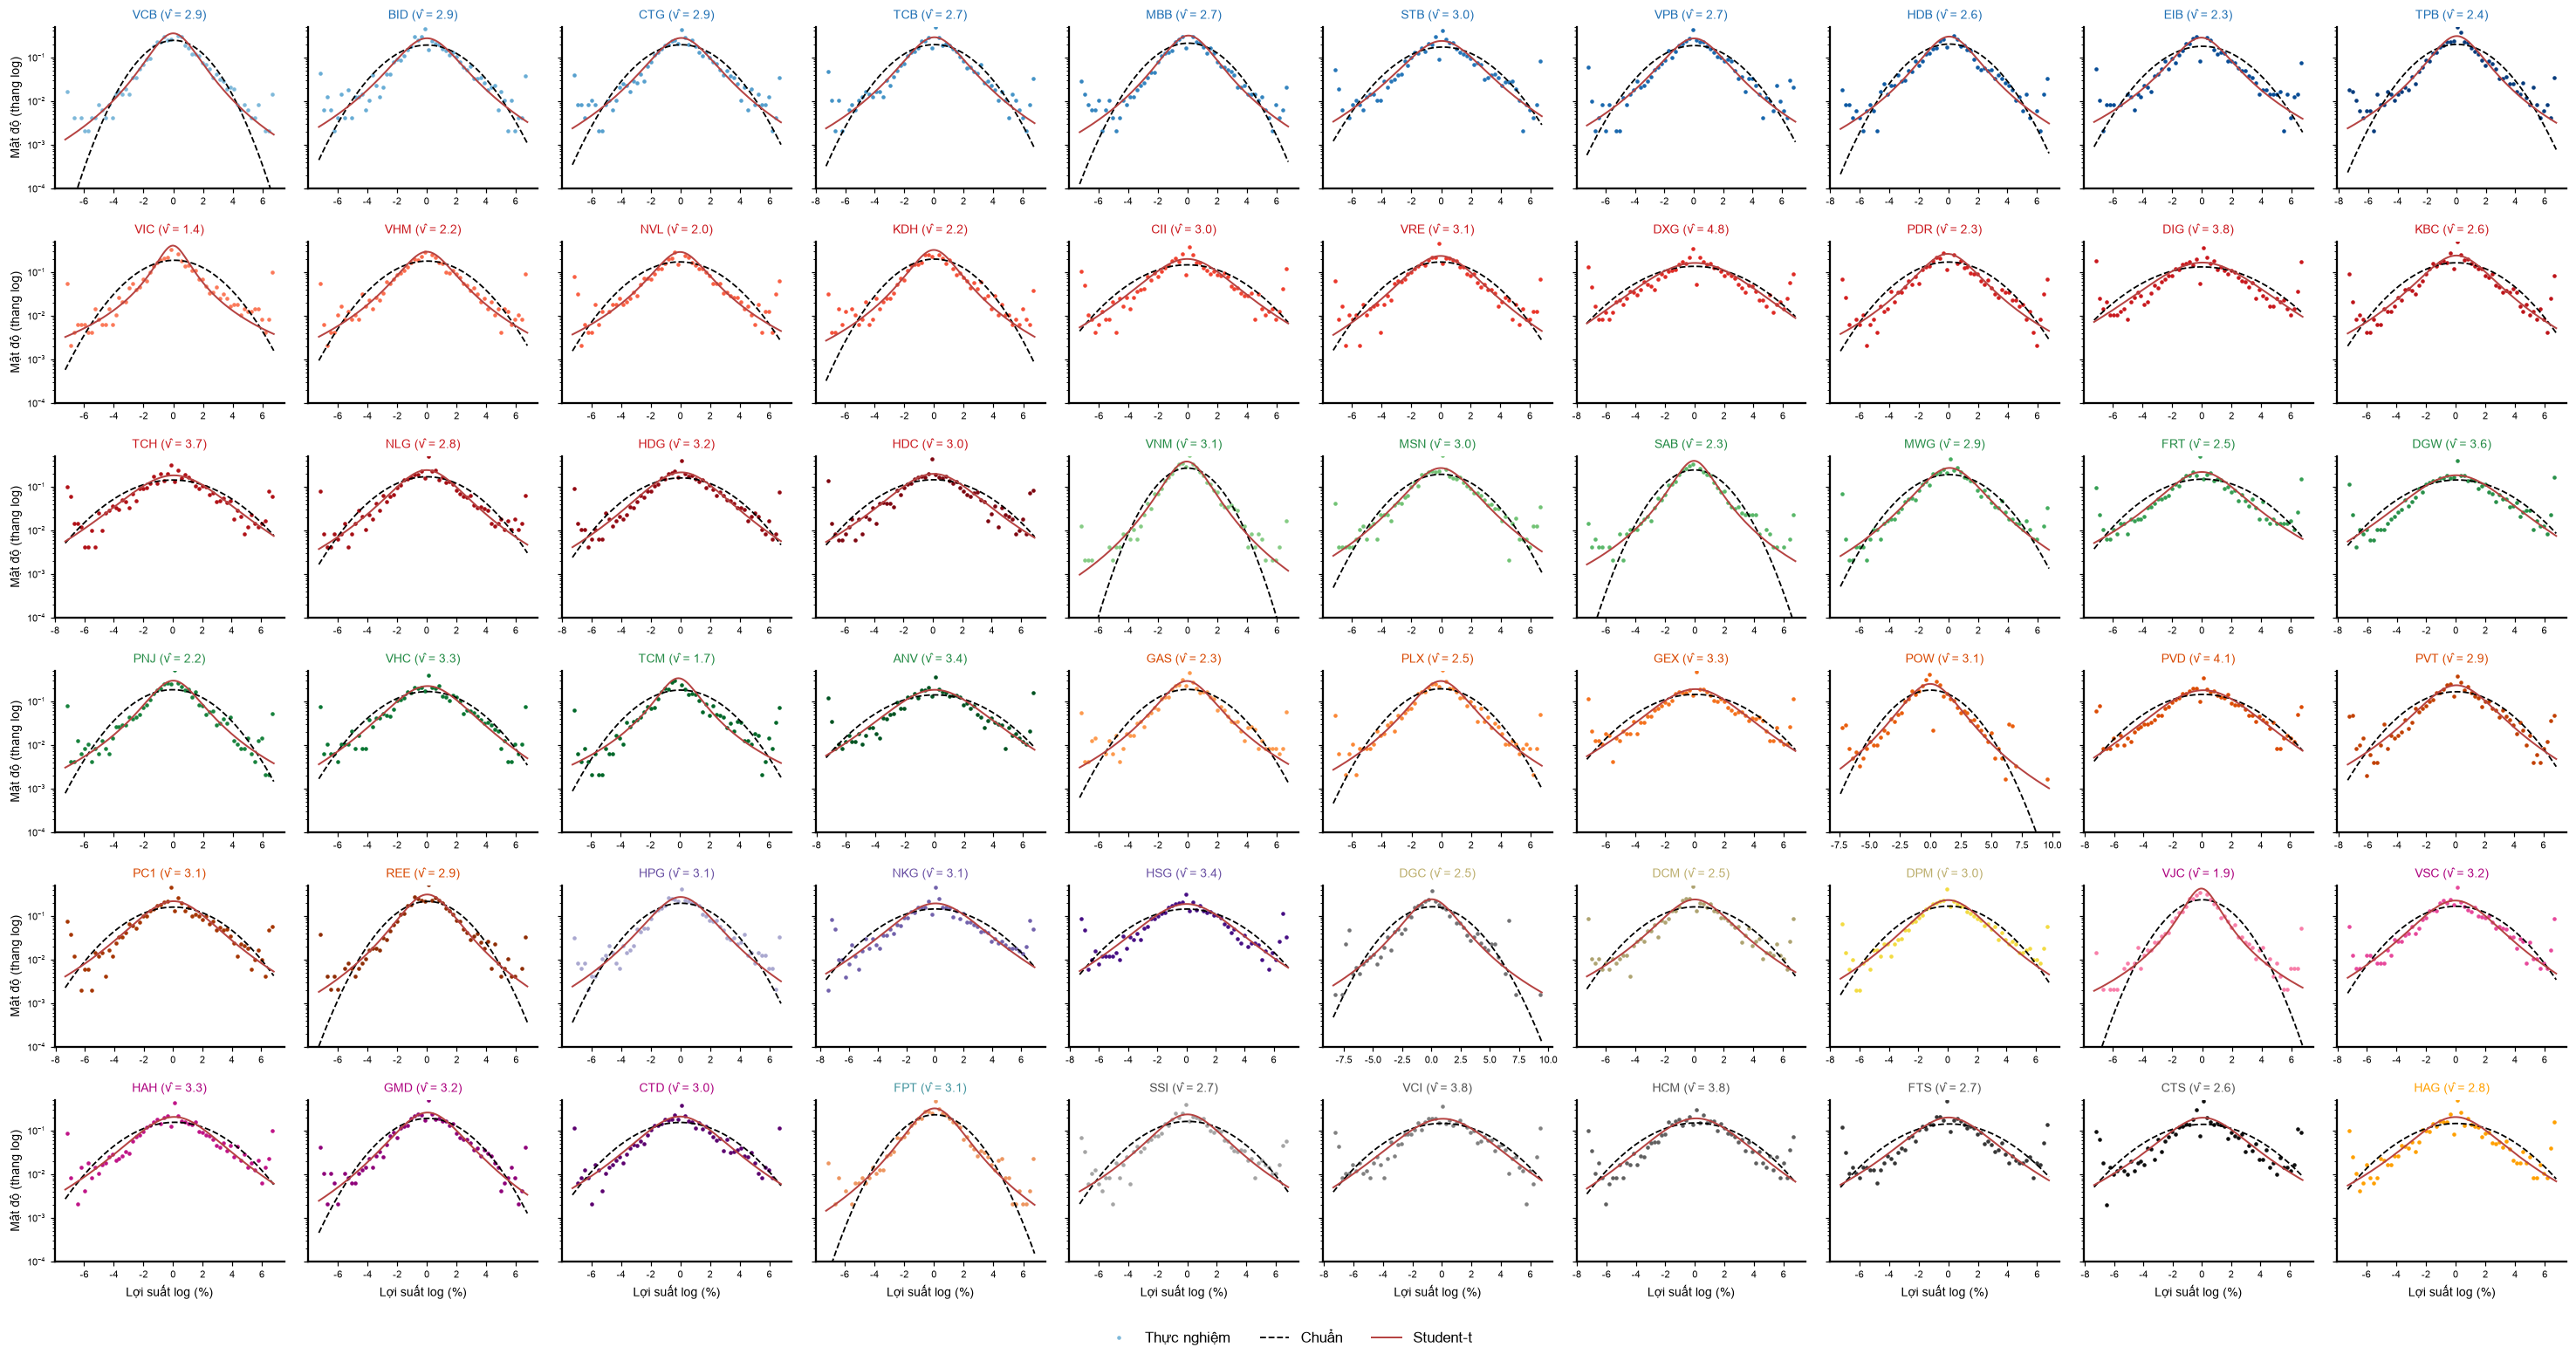

Số mã JB p < 0,001: 60 / 60


,S (độ lệch),K (độ nhọn vượt chuẩn),JB,JB p-value,ν̂ (Student-t),tỷ lệ r = 0
symbol,,,,,,
VCB,-0.0334,3.3296,971.8433,0.0000,2.8879,0.0823
BID,-0.2240,2.2493,460.9167,0.0000,2.8649,0.0675
CTG,-0.1863,2.3467,494.7149,0.0000,2.8943,0.0609
TCB,-0.2622,2.5561,596.6217,0.0000,2.7158,0.0747
MBB,-0.3274,3.0841,871.0446,0.0000,2.6972,0.0856
STB,-0.0026,1.6287,232.4434,0.0000,3.0354,0.0666
VPB,-0.1329,2.2725,458.7289,0.0000,2.7281,0.0942
HDB,-0.0468,2.2864,458.8466,0.0000,2.5908,0.1032
EIB,0.0779,2.2274,436.8531,0.0000,2.2859,0.1203


In [4]:
rows, fits = [], {}
for s in SYMBOLS:
    x = r[s].values
    jb = stats.jarque_bera(x)
    nu, loc, sc = stats.t.fit(x)
    fits[s] = (x.mean(), x.std(ddof=1), nu, loc, sc)
    rows.append({"symbol": s, "S (độ lệch)": stats.skew(x), "K (độ nhọn vượt chuẩn)": stats.kurtosis(x),
                 "JB": jb.statistic, "JB p-value": jb.pvalue, "ν̂ (Student-t)": nu, "tỷ lệ r = 0": np.mean(x == 0)})
shape = pd.DataFrame(rows).set_index("symbol")

fig, axes = plt.subplots(*U.symbol_grid(), figsize=U.symbol_grid_size(2.7, 2.3), sharey=True)
for ax, s in zip(axes.ravel(), SYMBOLS):
    x = r[s].values
    mu, sd, nu, loc, sc = fits[s]
    dens, edges = np.histogram(x, bins=60, density=True)
    mid = (edges[:-1] + edges[1:]) / 2
    ax.semilogy(100 * mid[dens > 0], dens[dens > 0] / 100, "o", ms=2, color=COL[s], label="Thực nghiệm")
    g = np.linspace(x.min(), x.max(), 300)
    ax.semilogy(100 * g, stats.norm.pdf(g, loc=mu, scale=sd) / 100, "--", color="black", lw=1.2, label="Chuẩn")
    ax.semilogy(100 * g, stats.t.pdf(g, nu, loc=loc, scale=sc) / 100, color=PAL["red_strong"], lw=1.3, label="Student-t")
    ax.set_title(f"{s} (ν̂ = {nu:.1f})", fontsize=9, color=SC[SECTOR[s]]); ax.set_ylim(1e-4, 0.5)
    ax.tick_params(labelsize=7)
for ax in axes[-1]: ax.set_xlabel("Lợi suất log (%)", fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("Mật độ (thang log)", fontsize=9)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=11)
U.finalize_figure(fig, "finding_3_fat_tails"); plt.show()
print("Số mã JB p < 0,001:", int((shape["JB p-value"] < 1e-3).sum()), f"/ {len(SYMBOLS)}")
shape

### Phân tích

- Độ nhọn vượt chuẩn $K$ = 0,45–4,28 > 0 ở **cả 60 mã** (thấp nhất DXG 0,45; cao nhất VJC 4,28, SAB, VNM ≈ 3,9), độ lệch $S$ gần 0 (−0,33 ở MBB đến +0,52 ở VJC); Jarque–Bera $JB$ = 26–1.686, p < 0,001 → **bác bỏ tính chuẩn** ở 60/60 mã.
  Mã vốn hoá lớn, biến động thấp (VJC, SAB, VNM, VCB) có độ nhọn cao nhất: phần lớn phiên rất êm, thỉnh thoảng có cú sốc lớn. Mã nhỏ biến động cao (DXG, DIG, chứng khoán) có độ nhọn **thấp** —
  không phải vì đuôi mỏng mà vì biên ±7% cắt đuôi của chúng rất sớm (Phát hiện 4).
- Bậc tự do Student-t $\hat\nu$ ≈ 1,4 (VIC) đến 4,9 (DXG). Student-t bị kéo bởi hai hiện tượng **không phải đuôi dày thật**: khối xác suất tại 0 (**4,9–12,5% số phiên đứng giá**; cao nhất KDH, EIB, TCM) làm đỉnh nhọn,
  và các điểm dồn tại ±7% ở rìa. Vì vậy không nên diễn giải $\hat\nu$ như chỉ số đuôi.
- Hệ quả: không dùng giả định chuẩn (theo AIC ở notebook 03, Laplace và Student-t tốt hơn chuẩn ở cả 60 mã).

## Phát hiện 4 — Biên độ ±7% của HOSE chặn đuôi phân phối

**Tính gì:** biên chặn lý thuyết của lợi suất log, tỷ lệ phiên đóng cửa ở giá trần/sàn, và độ (bất) ổn định của ước lượng
chỉ số đuôi Hill khi dữ liệu bị chặn.

**Công thức.**

- Giá trong phiên bị giới hạn $0{,}93\,P_{t-1} \le P_t \le 1{,}07\,P_{t-1}$, nên $\ln(0{,}93) \approx -0{,}0726 \le r_t \le \ln(1{,}07) \approx 0{,}0677$
  (lệch nhẹ do giá trần/sàn được làm tròn theo bước giá).
- Phiên **chạm trần**: $r^{\text{đơn}}_t \ge 6{,}5\%$ **và** $P_t = H_t$ (đóng cửa tại giá cao nhất); **chạm sàn**: $r^{\text{đơn}}_t \le -6{,}5\%$ và $P_t = L_t$.
- Ước lượng Hill cho đuôi lỗ: sắp xếp mức lỗ $X = -r > 0$ giảm dần $X_{(1)} \ge X_{(2)} \ge \dots$, với $k$ quan sát lớn nhất
  $$\hat\alpha_k = \left(\frac1k\sum_{j=1}^{k}\ln X_{(j)} - \ln X_{(k+1)}\right)^{-1}.$$
  Nếu đuôi theo luật lũy thừa $P(X > x) \propto x^{-\alpha}$ thì $\hat\alpha_k$ phải **ổn định** theo $k$. Khi nhiều quan sát dồn đúng một mức
  (mức sàn), $\ln X_{(j)} - \ln X_{(k+1)} \approx 0$ nên $\hat\alpha_k$ phình lên rất lớn.

**Các bước:** (1) đếm tỷ lệ phiên chạm trần/sàn trong khung (từ cờ `hit_ceiling`, `hit_floor` của CSDL);
(2) vẽ histogram phần đuôi $|r| > 4\%$ cùng hai vạch biên; (3) tính $\hat\alpha_k$ với $k = 10\ldots 150$ và vẽ theo $k$.

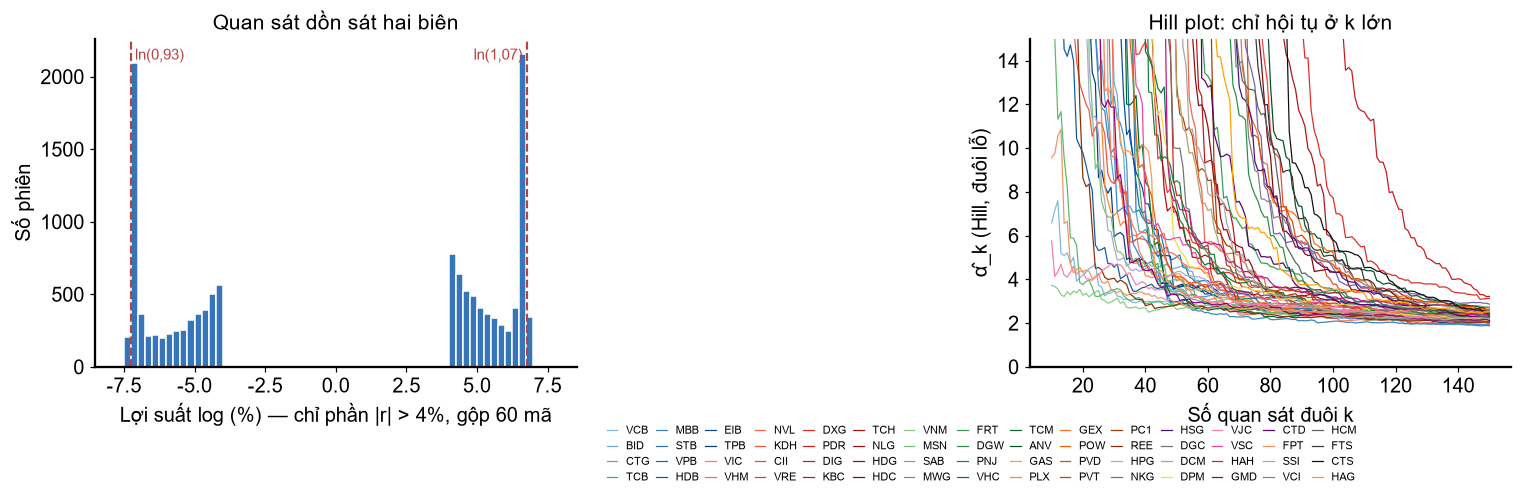

Gộp 60 mã: 1638 phiên có r > 6,65% (sát trần), 1410 phiên có r < −7,15% (sát sàn) trên 126,180 quan sát
Hill α̂ trung vị: k=25 → 93.7 | k=50 → 7.2 | k=100 → 2.63 (nhỏ nhất–lớn nhất 2.08–20.84)


,ty_le_tran,ty_le_san,α̂ (k=25),α̂ (k=50),α̂ (k=100)
VCB,0.0033,0.0038,3.7251,2.9711,2.3852
BID,0.0094,0.0132,18.5598,4.5364,2.5755
CTG,0.0080,0.0113,13.5237,3.4989,2.4107
TCB,0.0085,0.0127,50.4611,3.6863,2.2198
MBB,0.0057,0.0090,12.8382,2.9517,2.0811
STB,0.0203,0.0160,53.4399,5.0195,2.5964
VPB,0.0118,0.0160,59.2452,2.9858,2.4084
HDB,0.0094,0.0071,5.3141,3.6261,3.0785
EIB,0.0193,0.0137,54.6544,3.6177,2.3509
TPB,0.0090,0.0104,8.6480,3.6710,2.2768


In [5]:
hits = con.execute("""
    SELECT symbol, AVG(hit_ceiling::INT) AS ty_le_tran, AVG(hit_floor::INT) AS ty_le_san
    FROM v_analysis GROUP BY symbol""").df().set_index("symbol").loc[SYMBOLS]
UP, DOWN = np.log(1.07), np.log(0.93)

def hill(losses, ks):
    xs = np.sort(losses[losses > 0])[::-1]
    lx = np.log(xs)
    return np.array([1 / (lx[:k].mean() - lx[k]) for k in ks])

ks = np.arange(10, 151)
hill_curves = {s: hill(-r[s].values, ks) for s in SYMBOLS}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pooled = r.values.ravel()
bins = np.arange(-0.0775, 0.0776, 0.0025)
axes[0].hist(100 * pooled[np.abs(pooled) > 0.04], bins=100 * bins, color=PAL["blue_secondary"], edgecolor="white")
for b, lab in [(UP, "ln(1,07)"), (DOWN, "ln(0,93)")]:
    axes[0].axvline(100 * b, color=PAL["red_strong"], ls="--", lw=1.4)
    axes[0].text(100 * b + (-0.15 if b > 0 else 0.15), axes[0].get_ylim()[1] * 0.97, lab, color=PAL["red_strong"],
                 fontsize=10, ha="right" if b > 0 else "left", va="top")
axes[0].set_xlabel(f"Lợi suất log (%) — chỉ phần |r| > 4%, gộp {len(SYMBOLS)} mã"); axes[0].set_ylabel("Số phiên")
axes[0].set_title("Quan sát dồn sát hai biên")
for s in SYMBOLS:
    axes[1].plot(ks, hill_curves[s], color=COL[s], lw=0.8, label=s)
axes[1].set_ylim(0, 15); axes[1].set_xlabel("Số quan sát đuôi k"); axes[1].set_ylabel("α̂_k (Hill, đuôi lỗ)")
axes[1].set_title("Hill plot: chỉ hội tụ ở k lớn")
axes[1].legend(ncol=15, fontsize=7, loc="upper center", bbox_to_anchor=(-0.1, -0.15), columnspacing=0.6, handlelength=1.0)
U.finalize_figure(fig, "finding_4_price_limit_censoring"); plt.show()

hill_tab = pd.DataFrame({f"α̂ (k={k})": [hill_curves[s][ks == k][0] for s in SYMBOLS] for k in (25, 50, 100)},
                        index=SYMBOLS)
n_up = int(((pooled > 0.0665)).sum()); n_dn = int((pooled < -0.0715).sum())
print(f"Gộp {len(SYMBOLS)} mã: {n_up} phiên có r > 6,65% (sát trần), {n_dn} phiên có r < −7,15% (sát sàn) trên {len(pooled):,} quan sát")
print("Hill α̂ trung vị: k=25 → %.1f | k=50 → %.1f | k=100 → %.2f (nhỏ nhất–lớn nhất %.2f–%.2f)" % (
    hill_tab.iloc[:, 0].median(), hill_tab.iloc[:, 1].median(), hill_tab.iloc[:, 2].median(), hill_tab.iloc[:, 2].min(), hill_tab.iloc[:, 2].max()))
pd.concat([hits, hill_tab], axis=1)

### Phân tích

- Gộp 60 mã: **1.638 phiên sát trần và 1.410 phiên sát sàn** trên 126.180 quan sát (2,4%) — hai cột đột biến ngay tại biên; phân phối không "tắt dần" ra đuôi mà bị **cắt và dồn** tại biên.
  Mức bị chặn **rất khác nhau giữa các mã**: trần + sàn từ 0,6% (VNM), 0,7% (VCB) tới 9,2% (DIG), 8,7% (CTS), 7,9% (DXG) — chênh ~15 lần.
- **Hệ quả cho phân tích đuôi:** với $k = \lfloor n^{0{,}35}\rfloor = 14$ phiên cực trị mỗi đuôi, **54/60 mã có ≥ 14 phiên chạm trần và ≥ 14 phiên chạm sàn** — trên lợi suất thô, toàn bộ đuôi
  của chúng là các phiên trùng giá trị tại biên. Lọc GARCH (Processing) biến ngưỡng thành ±7%/σₜ thay đổi theo ngày nên xoá được sự trùng giá trị, nhưng không khôi phục được độ lớn bị cắt. Điều này **đã đúng** với 15/20 mã cũ (trừ VCB, MBB, VNM, SAB, FPT) — mở rộng mẫu không tạo ra vấn đề mới mà làm nó phổ biến hơn.
- Hill plot **không có vùng phẳng ở k nhỏ**: trung vị α̂ ở k = 25 là 94 (DIG 277, DGW 217), ở k = 50 là 7,2; ở k = 100 trung vị 2,63 nhưng DIG vẫn 20,8, DXG 7,7. Chỉ các mã ít bị chặn (VNM, VCB, SAB)
  có α̂ ổn định (k = 25: 3,2–3,7). Dữ liệu ngày của HOSE là **dữ liệu bị kiểm duyệt (censored)** ở đuôi; phân tích đuôi cần EVT có kiểm duyệt, lợi suất tuần, hoặc phương pháp chỉ dùng hạng (như hệ số nhân quả đuôi).

## Phát hiện 5 — Biến động cụm (volatility clustering)

**Tính gì:** hàm tự tương quan (ACF) của lợi suất $r_t$ và của độ lớn $|r_t|$; kiểm định Ljung–Box; biến động trượt 20 phiên
trung bình của 60 mã (và của từng ngành) theo thời gian.

**Công thức.**

- ACF ở độ trễ $h$: $\hat\rho(h) = \dfrac{\sum_{t=h+1}^{T}(x_t-\bar x)(x_{t-h}-\bar x)}{\sum_{t=1}^{T}(x_t-\bar x)^2}$, áp dụng cho $x_t = r_t$ và $x_t = |r_t|$.
  Dải tin cậy 95% khi không có tự tương quan: $\pm 1{,}96/\sqrt{T}$.
- Ljung–Box: $Q(m) = T(T+2)\sum_{h=1}^{m}\dfrac{\hat\rho(h)^2}{T-h} \sim \chi^2_m$ dưới $H_0$: không tự tương quan đến độ trễ $m$ (dùng $m = 10$).
- Biến động 20 phiên năm hoá: $\hat\sigma_{i,t}^{(20)} = \sqrt{252}\cdot\text{sd}(r_{i,t-19},\dots,r_{i,t})$ (cột `vol_20d` tính sẵn trong CSDL).

**Ý tưởng:** nếu $r_t$ gần như không tự tương quan nhưng $|r_t|$ tự tương quan dương kéo dài, thì **hướng** biến động khó dự báo
nhưng **độ lớn** biến động dự báo được — phiên biến động mạnh có xu hướng đi theo cụm. Đây là dấu hiệu của hiệu ứng ARCH/GARCH.

**Các bước:** (1) tính ACF đến 30 độ trễ cho $r_t$ và $|r_t|$ từng mã; (2) Ljung–Box với $m=10$ cho $r_t$ và $r_t^2$;
(3) lấy `vol_20d` từ CSDL, lấy trung bình 60 mã và từng ngành, đánh dấu đỉnh.

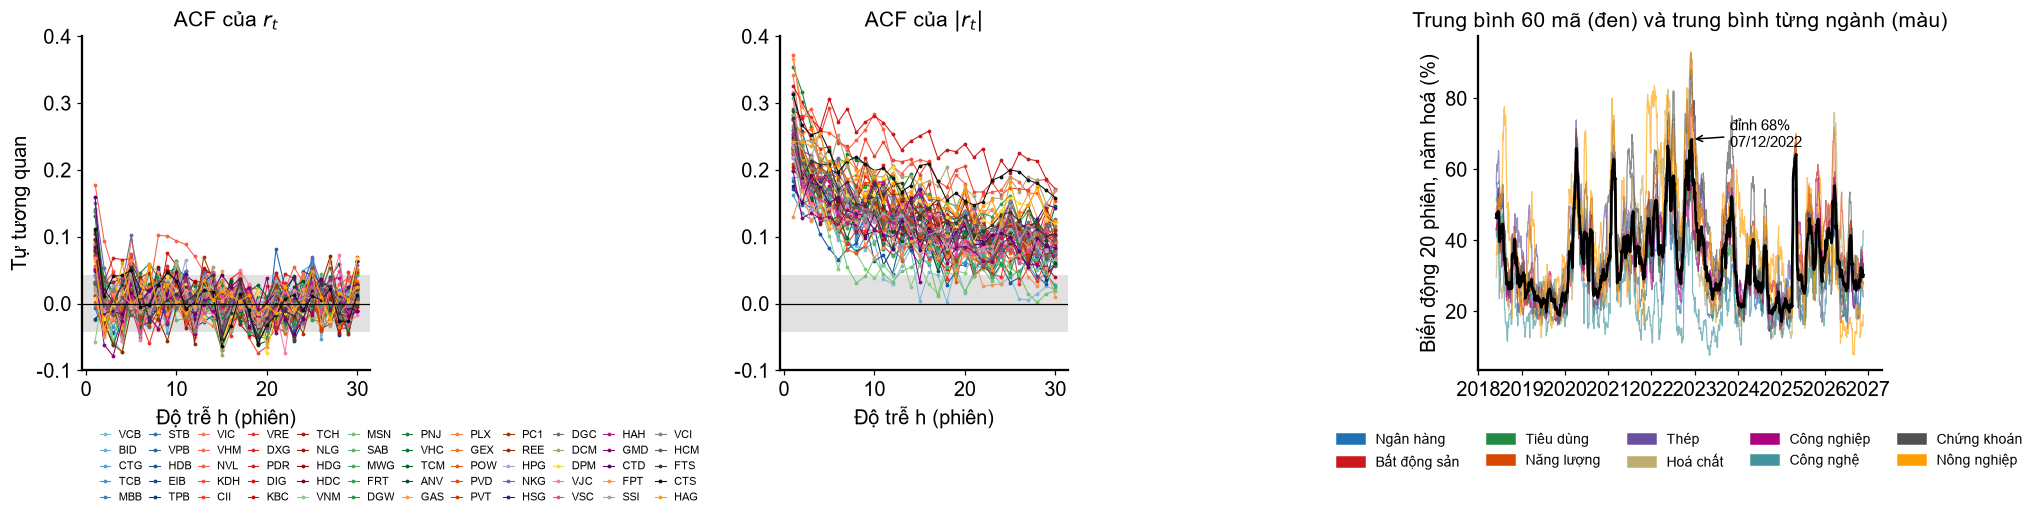

Biến động 20 phiên TB 60 mã: đỉnh 68% (07/12/2022), thấp nhất 17% (03/01/2025)
Q(10) của r có p < 5%: 44 / 60 | Q(10) của r² có p < 1%: 60 / 60
ρ̂(1) của |r|: min 0.13 (FPT), max 0.37 (NVL)


,Q(10) của r: p,Q(10) của r²: p,ρ̂(1) của |r|
VCB,0.0459,0.0000,0.2273
BID,0.2009,0.0000,0.2189
CTG,0.0187,0.0000,0.1875
TCB,0.0015,0.0000,0.1624
MBB,0.7892,0.0000,0.1981
STB,0.2763,0.0000,0.2246
VPB,0.0003,0.0000,0.1840
HDB,0.1927,0.0000,0.1712
EIB,0.0211,0.0000,0.3131
TPB,0.1517,0.0000,0.2474


In [6]:
LAGS = 30
band = 1.96 / np.sqrt(len(r))
vol_s = con.execute("SELECT time, symbol, vol_20d * SQRT(252) AS v FROM v_analysis").df() \
           .pivot(index="time", columns="symbol", values="v")[SYMBOLS]
vol = vol_s.mean(axis=1)                                  # trung bình mọi mã

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for s in SYMBOLS:
    axes[0].plot(range(1, LAGS + 1), acf(r[s], nlags=LAGS)[1:], color=COL[s], lw=0.7, marker="o", ms=1.5, label=s)
    axes[1].plot(range(1, LAGS + 1), acf(r[s].abs(), nlags=LAGS)[1:], color=COL[s], lw=0.7, marker="o", ms=1.5)
for ax, t in zip(axes[:2], ["ACF của $r_t$", "ACF của $|r_t|$"]):
    ax.axhspan(-band, band, color=PAL["neutral"], alpha=0.6, lw=0)
    ax.axhline(0, color="black", lw=0.8); ax.set_ylim(-0.1, 0.4)
    ax.set_title(t); ax.set_xlabel("Độ trễ h (phiên)")
axes[0].set_ylabel("Tự tương quan")
axes[0].legend(ncol=12, fontsize=7, loc="upper center", bbox_to_anchor=(1.1, -0.15), columnspacing=0.6, handlelength=1.0)
for sec in SECTORS:
    members = [s for s in SYMBOLS if SECTOR[s] == sec]
    axes[2].plot(vol_s.index, 100 * vol_s[members].mean(axis=1), color=SC[sec], lw=0.8, alpha=0.65)
axes[2].plot(vol.index, 100 * vol, color="black", lw=1.8, label=f"Trung bình {len(SYMBOLS)} mã")
peak = vol.idxmax()
axes[2].annotate(f"đỉnh {100*vol.max():.0f}%\n{peak:%d/%m/%Y}", (peak, 100 * vol.max()), xytext=(25, -5),
                 textcoords="offset points", fontsize=10, arrowprops=dict(arrowstyle="->", lw=1))
axes[2].set_ylabel("Biến động 20 phiên, năm hoá (%)"); axes[2].set_title(f"Trung bình {len(SYMBOLS)} mã (đen) và trung bình từng ngành (màu)")
sector_legend(axes[2], loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, fontsize=9)
U.finalize_figure(fig, "finding_5_volatility_clustering"); plt.show()

lb = pd.DataFrame({s: {"Q(10) của r: p": acorr_ljungbox(r[s], lags=[10])["lb_pvalue"].iloc[0],
                       "Q(10) của r²: p": acorr_ljungbox(r[s] ** 2, lags=[10])["lb_pvalue"].iloc[0],
                       "ρ̂(1) của |r|": acf(r[s].abs(), nlags=1)[1]} for s in SYMBOLS}).T
print(f"Biến động 20 phiên TB {len(SYMBOLS)} mã: đỉnh {100*vol.max():.0f}% ({peak:%d/%m/%Y}), thấp nhất {100*vol.min():.0f}% ({vol.idxmin():%d/%m/%Y})")
print("Q(10) của r có p < 5%:", int((lb["Q(10) của r: p"] < .05).sum()), f"/ {len(SYMBOLS)} | Q(10) của r² có p < 1%:", int((lb["Q(10) của r²: p"] < .01).sum()), f"/ {len(SYMBOLS)}")
print("ρ̂(1) của |r|: min %.2f (%s), max %.2f (%s)" % (lb["ρ̂(1) của |r|"].min(), lb["ρ̂(1) của |r|"].idxmin(), lb["ρ̂(1) của |r|"].max(), lb["ρ̂(1) của |r|"].idxmax()))
lb

### Phân tích

- ACF của **$r_t$** nhỏ về biên độ, nhưng Ljung–Box Q(10) có p < 5% ở **44/60 mã** — nhiều hơn tỷ lệ ở 20 mã cũ, chủ yếu do mã vừa và nhỏ (CII, PDR, DIG, NKG, FRT, PNJ: p < 0,001); không có ý nghĩa ở MBB, NLG, POW, DCM, HPG, STB, BID
  → hướng giá chỉ dự báo được rất yếu.
- ACF của **$|r_t|$** dương ở cả 30 độ trễ, $\hat\rho(1)$ từ 0,13 (FPT) đến 0,37 (NVL; GAS 0,37, PNJ 0,35, VIC 0,34); Q(10) của $r_t^2$ có p ≈ 0 ở **60/60 mã** → **độ lớn** biến động có trí nhớ dài.
- Biến động 20 phiên trung bình 60 mã đạt **đỉnh 68% ngày 07/12/2022** (sau đợt sập tháng 11/2022) và thấp nhất 17% ngày 03/01/2025; đường trung bình từng ngành (màu) cùng tăng vọt trong các đợt chung
  (03–04/2020, 2021, 11–12/2022, 04/2025) → cụm biến động mang tính **hệ thống**.
- Hệ quả: **lọc GARCH** (hoặc sai số HAC) trước khi phân tích quan hệ giữa các mã.

## Phát hiện 6 — Một nhân tố thị trường chung, cộng nhân tố riêng của Vingroup/bất động sản và của năng lượng – tiêu dùng

**Tính gì:** ma trận tương quan Pearson giữa lợi suất 60 mã và phân tích thành phần chính (PCA) trên ma trận đó.

**Công thức.**

- Tương quan Pearson: $\rho_{ij} = \dfrac{\sum_t (r_{i,t}-\bar r_i)(r_{j,t}-\bar r_j)}{\sqrt{\sum_t (r_{i,t}-\bar r_i)^2}\sqrt{\sum_t (r_{j,t}-\bar r_j)^2}} \in [-1, 1]$.
- PCA: chuẩn hoá $z_{i,t} = (r_{i,t}-\bar r_i)/s_i$, phân rã ma trận tương quan $\mathbf R = \mathbf V\boldsymbol\Lambda\mathbf V^\top$ với
  $\lambda_1 \ge \dots \ge \lambda_{60}$. Thành phần thứ $k$: $PC_{k,t} = \sum_i v_{ik} z_{i,t}$; tỷ lệ phương sai giải thích $\lambda_k / \sum_j \lambda_j$.
  Hệ số tải $v_{ik}$ cho biết mã $i$ đóng góp bao nhiêu vào thành phần $k$.

**Đọc kết quả:** nếu PC1 có hệ số tải **cùng dấu, gần bằng nhau** ở mọi mã thì PC1 là "nhân tố thị trường" — mọi mã cùng lên
cùng xuống. Các PC sau mô tả phần **riêng** của từng nhóm/mã.

**Các bước:** (1) tính $\mathbf R$; (2) phân rã trị riêng, sắp giảm dần, cố định dấu véc-tơ riêng để tổng hệ số tải dương;
(3) vẽ heatmap tương quan 60×60 (nhãn tô màu theo ngành, vạch đen phân cách ngành), cột phương sai giải thích và heatmap hệ số tải PC1–PC3. So với ngưỡng nhiễu Marchenko–Pastur $\lambda_{\max}=(1+\sqrt{N/T})^2$ ($N=60$ mã, $T$ phiên) để biết có bao nhiêu thành phần chứa tín hiệu thật.

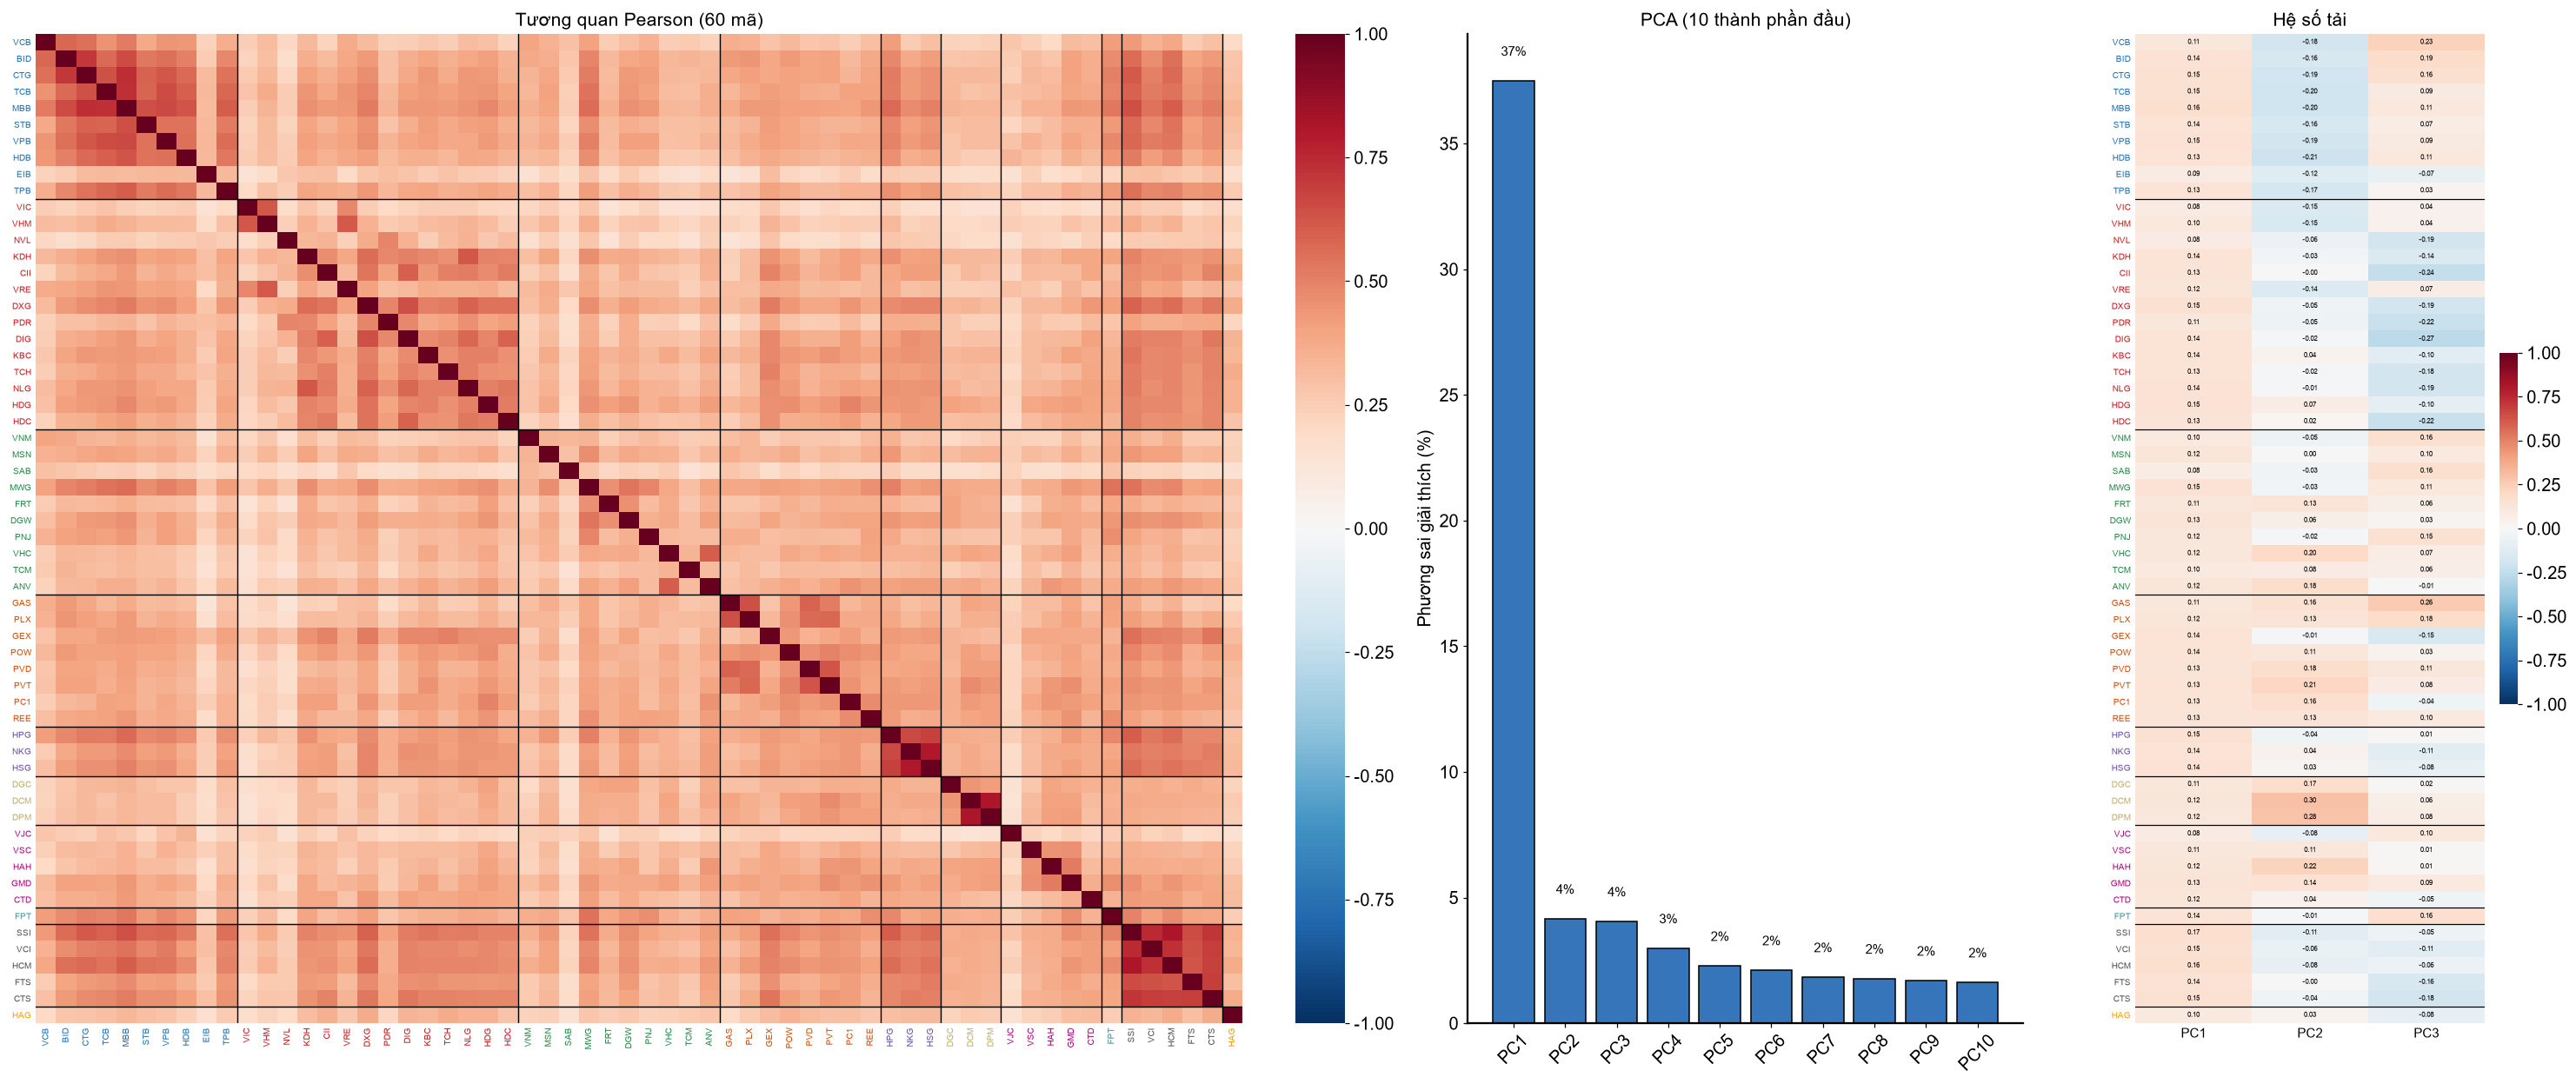

Tương quan 1770 cặp: min 0.13 (EIB–GAS) | TB 0.35 | max 0.81 (SSI–HCM)
Cao nhất: {'VCI–HCM': 0.73, 'CTG–MBB': 0.74, 'SSI–VCI': 0.75, 'NKG–HSG': 0.8, 'DCM–DPM': 0.81, 'SSI–HCM': 0.81}
Thấp nhất: {'EIB–GAS': 0.13, 'NVL–GAS': 0.13, 'VIC–FRT': 0.13, 'DCM–VJC': 0.13, 'NVL–FRT': 0.14, 'VIC–VHC': 0.14}
TB cùng ngành 0.432 | khác ngành 0.343
Phương sai giải thích PC1–PC5 (%): [37.5, 4.2, 4.0, 3.0, 2.3] | λ1 = 22.50, ngưỡng MP = 1.37, số trị riêng vượt ngưỡng: 4
PC1: tải nhỏ nhất SAB 0.08 | lớn nhất SSI 0.17
PC2 {'DCM': 0.3, 'DPM': 0.28, 'HAH': 0.22, 'HDB': -0.21}
PC3 {'DIG': -0.27, 'GAS': 0.26, 'CII': -0.24, 'VCB': 0.23}


,PC1,PC2,PC3
VCB,0.1100,-0.1800,0.2300
BID,0.1400,-0.1600,0.1900
CTG,0.1500,-0.1900,0.1600
TCB,0.1500,-0.2000,0.0900
MBB,0.1600,-0.2000,0.1100
...,...,...,...
HCM,0.1600,-0.0800,-0.0600
FTS,0.1400,-0.0000,-0.1600
CTS,0.1500,-0.0400,-0.1800
HAG,0.1000,0.0300,-0.0800


In [7]:
R = r.corr()
eigval, eigvec = np.linalg.eigh(R.values)
order = eigval.argsort()[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
eigvec *= np.sign(eigvec.sum(axis=0))
explained = eigval / eigval.sum()
pcs = [f"PC{k+1}" for k in range(len(SYMBOLS))]
loadings = pd.DataFrame(eigvec, index=SYMBOLS, columns=pcs)
mp_max = (1 + np.sqrt(len(SYMBOLS) / len(r))) ** 2           # ngưỡng Marchenko–Pastur của trị riêng nhiễu thuần tuý

fig, axes = plt.subplots(1, 3, figsize=(27, 11.5), gridspec_kw={"width_ratios": [1.9, 0.8, 0.55]})
big_heatmap(axes[0], R, annotate=False, vmin=-1, vmax=1, title=f"Tương quan Pearson ({len(SYMBOLS)} mã)")
sector_style(axes[0], SYMBOLS, fs=6.5)
K = 10
axes[1].bar(pcs[:K], 100 * explained[:K], color=PAL["blue_secondary"], edgecolor="black", lw=1)
for k, v in enumerate(explained[:K]):
    axes[1].text(k, 100 * v + 1, f"{100*v:.0f}%", ha="center", fontsize=10)
axes[1].set_ylabel("Phương sai giải thích (%)"); axes[1].set_title(f"PCA ({K} thành phần đầu)")
axes[1].tick_params(axis="x", rotation=45)
U.make_heatmap(axes[2], loadings[pcs[:3]], vmin=-1, vmax=1, title="Hệ số tải")
for t in axes[2].texts: t.set_fontsize(5.5)
sector_style(axes[2], SYMBOLS, axis="y", sep=False, fs=6.5)
axes[2].set_xticks(range(3), pcs[:3], rotation=0, fontsize=10)
for i in range(1, len(SYMBOLS)):
    if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: axes[2].axhline(i - 0.5, color="black", lw=0.8)
U.finalize_figure(fig, "finding_6_correlation_pca"); plt.show()

off = pd.Series(R.values[iu], index=pair_names).sort_values()
print(f"Tương quan {len(pairs)} cặp:" + " min %.2f (%s) | TB %.2f | max %.2f (%s)" % (off.min(), off.index[0], off.mean(), off.max(), off.index[-1]))
print("Cao nhất:", off.tail(6).round(2).to_dict()); print("Thấp nhất:", off.head(6).round(2).to_dict())
print("TB cùng ngành %.3f | khác ngành %.3f" % (R.values[iu][same_sector].mean(), R.values[iu][~same_sector].mean()))
print("Phương sai giải thích PC1–PC5 (%):", (100 * explained[:5]).round(1).tolist(), "| λ1 = %.2f, ngưỡng MP = %.2f, số trị riêng vượt ngưỡng: %d" % (eigval[0], mp_max, (eigval > mp_max).sum()))
print("PC1: tải nhỏ nhất %s %.2f | lớn nhất %s %.2f" % (loadings.PC1.idxmin(), loadings.PC1.min(), loadings.PC1.idxmax(), loadings.PC1.max()))
for pc in ("PC2", "PC3"):
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, {s: round(float(loadings.loc[s, pc]), 2) for s in top})
pd.concat([loadings[pcs[:3]], pd.DataFrame([explained[:3]], index=["tỷ lệ giải thích"], columns=pcs[:3])]).round(2)

### Phân tích

- Tương quan Pearson của 1.770 cặp **đều dương**, 0,13–0,81 (trung bình 0,35); **cùng ngành 0,43, khác ngành 0,34**. Cao nhất là các ngành hẹp: **SSI–HCM 0,81**, **DCM–DPM 0,81** (phân bón), **NKG–HSG 0,80** (tôn thép),
  SSI–VCI 0,75, CTG–MBB 0,74. Thấp nhất: EIB–GAS, NVL–GAS, VIC–FRT (0,13).
- **PC1 giải thích 37,5% phương sai** (λ₁ = 22,5, ngưỡng nhiễu Marchenko–Pastur 1,37), tải dương ở cả 60 mã (0,08 ở SAB đến 0,17 ở SSI) → **nhân tố thị trường**.
  Bốn trị riêng vượt ngưỡng nhiễu nhưng PC2–PC4 chỉ 3–4% mỗi thành phần: **PC2** đối lập hoá chất/cảng biển (DCM, DPM, HAH) với ngân hàng; **PC3** đối lập nhóm phòng thủ vốn hoá lớn (GAS, VCB, BID)
  với bất động sản nhỏ (DIG, CII); **PC4** là Vingroup (VIC, VHM, VRE).
- So với 20 mã (PC1 43%, PC2 Vingroup 6,8%): khi thêm mã vừa và nhỏ, nhân tố thị trường chiếm tỷ trọng nhỏ hơn và phần còn lại phân tán thành **nhiều nhân tố ngành hẹp**, mỗi nhân tố chỉ chung cho 2–5 mã.
- Hệ quả: kiểm soát nhân tố thị trường là cần nhưng chưa đủ; các cặp cùng ngành hẹp (chứng khoán, thép, phân bón) sẽ còn phụ thuộc mạnh sau khi khử thị trường.

## Phát hiện 7 — Phụ thuộc đuôi dưới mạnh hơn mức phân phối chuẩn cho phép

**Tính gì:** xác suất hai mã **cùng** rơi vào nhóm 5% phiên tệ nhất của chính nó, so với xác suất đó nếu cấu trúc phụ thuộc là
chuẩn (Gaussian copula) có cùng tương quan; kèm khoảng tin cậy bằng bootstrap khối.

**Công thức.**

- Đổi lợi suất sang hạng chuẩn hoá (giả-quan sát copula): $U_{i,t} = \text{rank}(r_{i,t})/(T+1) \in (0,1)$ — loại bỏ ảnh hưởng của phân phối biên, chỉ giữ cấu trúc phụ thuộc.
- Hệ số phụ thuộc đuôi dưới thực nghiệm tại mức $q$:
  $$\hat\lambda_L(q) = \frac{\#\{t : U_{i,t}\le q,\ U_{j,t}\le q\}}{T\,q} \approx P(U_j \le q \mid U_i \le q).$$
  Nếu hai mã độc lập, $\hat\lambda_L(q) \approx q = 0{,}05$; nếu luôn cùng sập, $\hat\lambda_L = 1$.
- Mức tham chiếu Gaussian: $\lambda_{G}(q) = \Phi_2\big(\Phi^{-1}(q), \Phi^{-1}(q); \rho\big)/q$, trong đó $\Phi_2$ là hàm phân phối chuẩn hai chiều
  với tương quan $\rho = 2\sin(\pi\rho_S/6)$ suy từ tương quan hạng Spearman $\rho_S$ (công thức đúng cho Gaussian copula).
- **Bootstrap khối** (giữ cấu trúc biến động cụm): lấy ngẫu nhiên các khối 20 phiên liên tiếp có hoàn lại cho đủ $T$ phiên,
  tính lại $\hat\lambda_L - \lambda_G$; lặp $B = 1.000$ lần, lấy phân vị 2,5% và 97,5% làm khoảng tin cậy 95%.

**Các bước:** (1) tính $U$; (2) với 1.770 cặp (60 mã), tính $\hat\lambda_L(0{,}05)$ và $\lambda_G$; (3) bootstrap khối;
(4) vẽ heatmap $\hat\lambda_L$ 60×60 và đồ thị phân tán $\hat\lambda_L$ theo $\lambda_G$ (thanh sai số là khoảng tin cậy của mức chênh). $\lambda_G$ phụ thuộc duy nhất vào $\rho$ nên được tính sẵn trên lưới $\rho$ rồi nội suy (sai số nội suy < $10^{-4}$), nhờ đó bootstrap 1.770 cặp × 1.000 lần chạy nhanh.

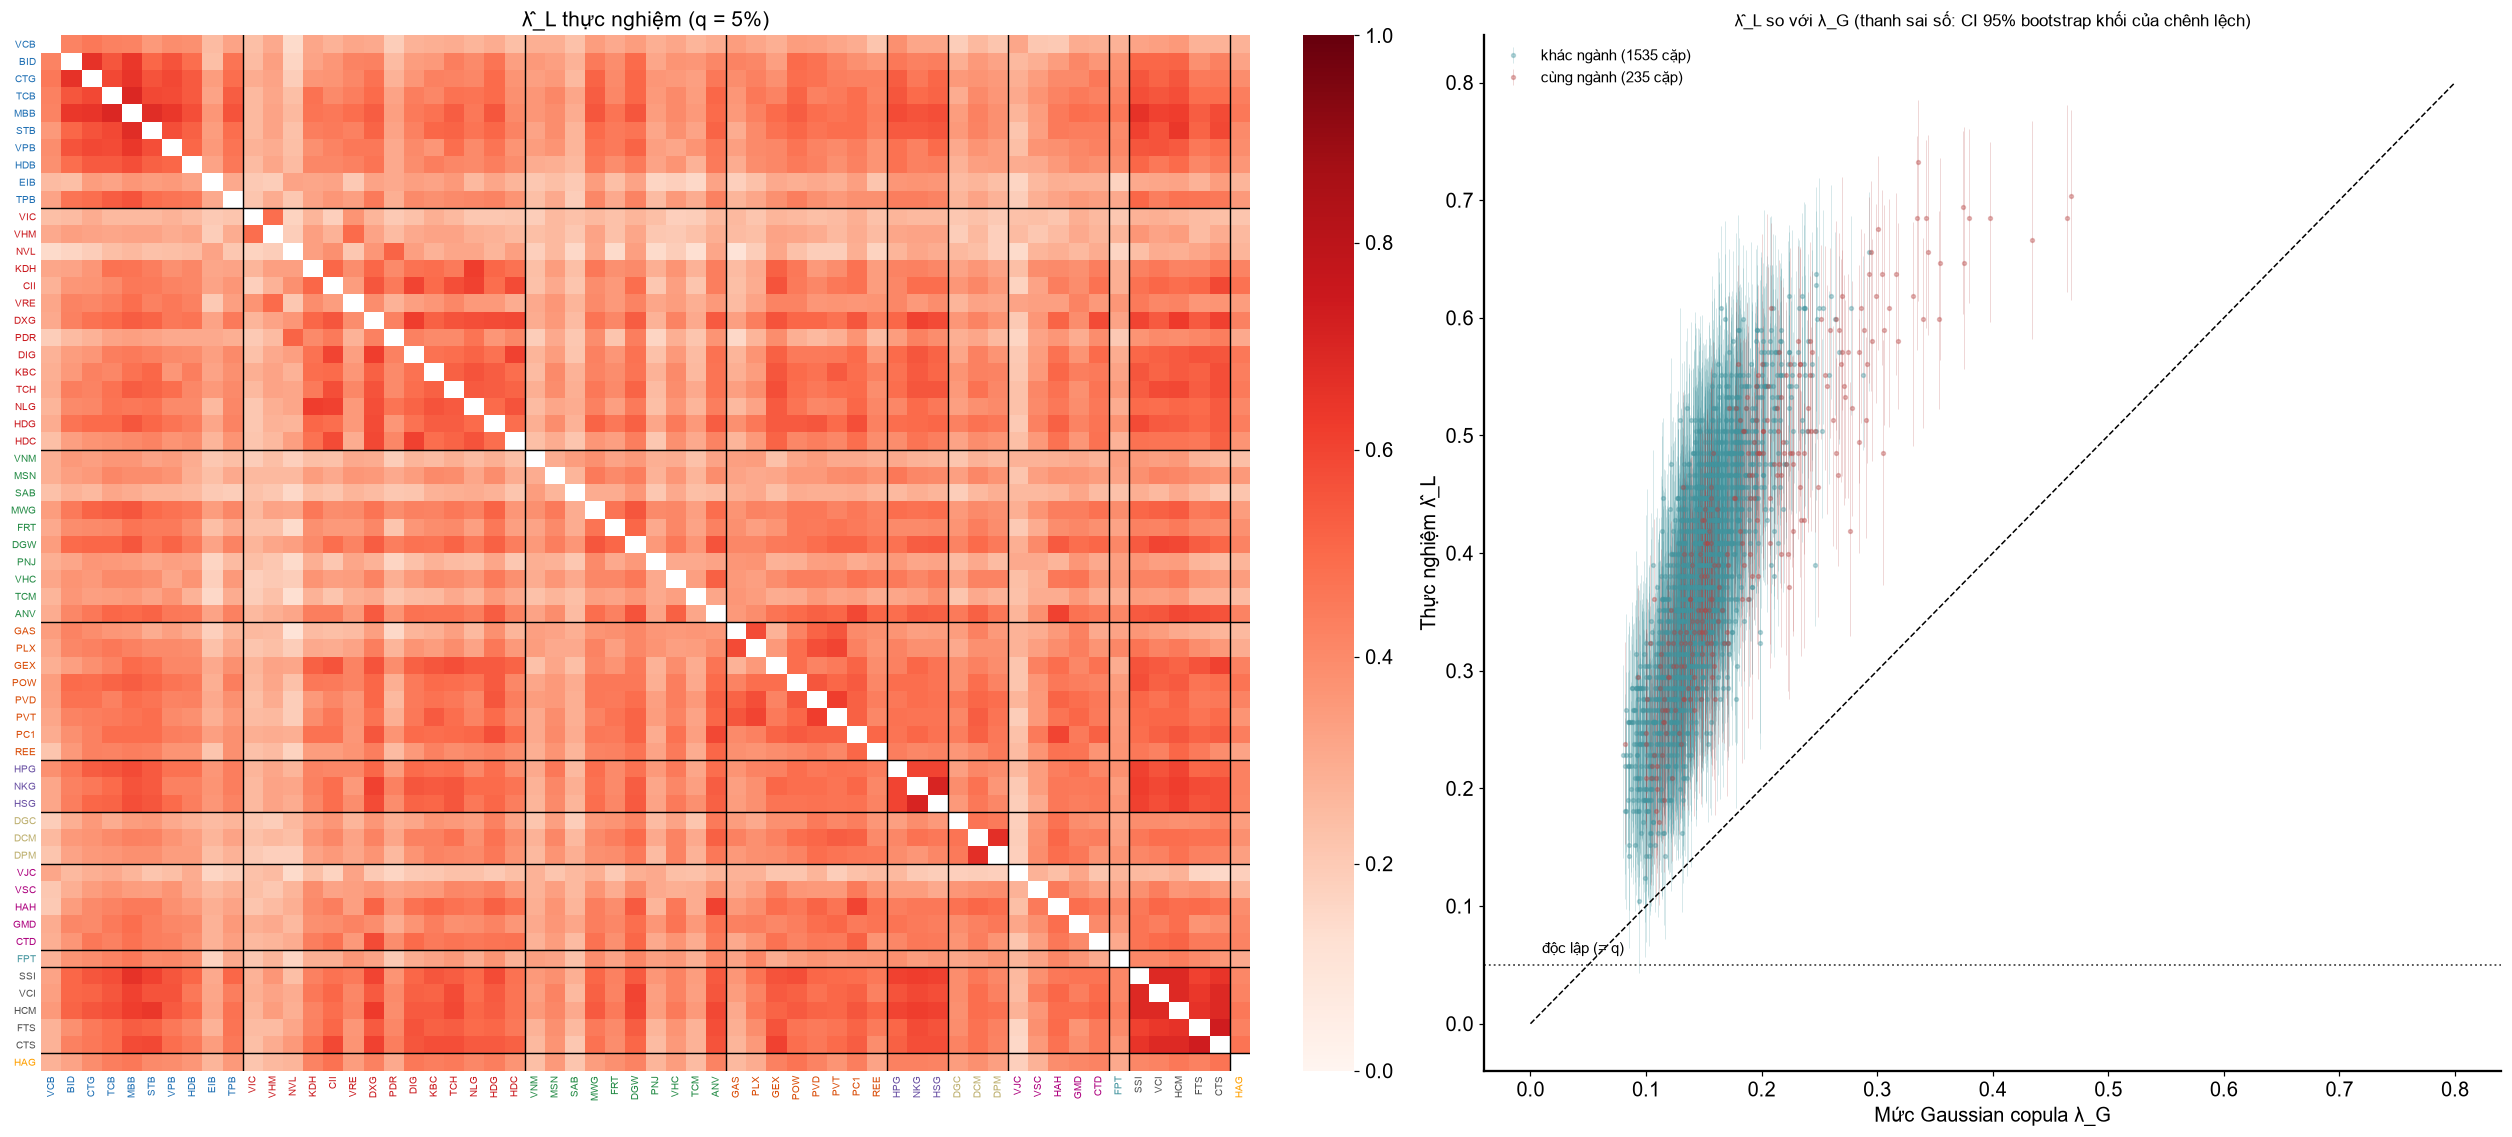

B = 1000, khối 20 phiên. λ̂_L TB 0.387 (độc lập = 0.05); λ_Gauss TB 0.155; tỷ số λ̂_L/λ_G: min 1.11 | TB 2.52 | max 3.96
Chênh lệch dương: 1770/1770; CI loại trừ 0: 1746/1770 (CI từng cặp, chưa hiệu chỉnh đa kiểm định)
cùng ngành: λ̂_L TB 0.433 | λ_G TB 0.196 | chênh lệch TB 0.236 | CI>0: 233/235
khác ngành: λ̂_L TB 0.380 | λ_G TB 0.148 | chênh lệch TB 0.232 | CI>0: 1513/1535


,λ̂_L,λ_Gauss,chênh lệch,"CI 2,5%","CI 97,5%",cùng ngành,CI loại trừ 0
FTS–CTS,0.7323,0.3355,0.3968,0.2789,0.4499,True,True
NKG–HSG,0.7038,0.4681,0.2357,0.1471,0.3082,True,True
TCB–MBB,0.6942,0.3746,0.3197,0.2285,0.3841,True,True
SSI–VCI,0.6847,0.3972,0.2875,0.1994,0.3519,True,True
SSI–HCM,0.6847,0.4644,0.2203,0.1571,0.3163,True,True
VCI–CTS,0.6847,0.3422,0.3426,0.2488,0.4086,True,True
VCI–HCM,0.6847,0.3794,0.3054,0.2336,0.3810,True,True
HCM–CTS,0.6847,0.3347,0.3501,0.2378,0.4196,True,True


In [8]:
Q, BLOCK, B = 0.05, 20, 1000
zq = stats.norm.ppf(Q)
RH = np.linspace(-0.95, 0.99, 300)                      # λ_Gauss(ρ) tính sẵn trên lưới rồi nội suy (nhanh khi bootstrap 1.770 cặp)
LG = np.array([stats.multivariate_normal([0, 0], [[1, p], [p, 1]]).cdf([zq, zq]) for p in RH]) / Q

def tail_mats(x):
    n = len(x)
    ranks = rankdata(x, axis=0)
    ind = (ranks / (n + 1) <= Q).astype(float)
    lam = ind.T @ ind / (n * Q)
    rho = 2 * np.sin(np.pi / 6 * np.corrcoef(ranks.T))
    return lam, np.interp(rho, RH, LG)

lam_emp, lam_g = tail_mats(r.values)
rng = np.random.default_rng(42)
starts_all = np.arange(len(r) - BLOCK + 1)
boot = np.empty((B, len(pairs)))
for b in range(B):
    idx = (rng.choice(starts_all, size=int(np.ceil(len(r) / BLOCK)))[:, None] + np.arange(BLOCK)).ravel()[:len(r)]
    lb_, gb_ = tail_mats(r.values[idx])
    boot[b] = (lb_ - gb_)[iu]

tail = pd.DataFrame({"λ̂_L": lam_emp[iu], "λ_Gauss": lam_g[iu]}, index=pair_names)
tail["chênh lệch"] = tail["λ̂_L"] - tail["λ_Gauss"]
tail["CI 2,5%"] = np.percentile(boot, 2.5, axis=0)
tail["CI 97,5%"] = np.percentile(boot, 97.5, axis=0)
tail["cùng ngành"] = same_sector
tail["CI loại trừ 0"] = tail["CI 2,5%"] > 0

lamL = pd.DataFrame(lam_emp, index=SYMBOLS, columns=SYMBOLS).mask(np.eye(len(SYMBOLS), dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(23, 10.5), gridspec_kw={"width_ratios": [1.3, 1]})
big_heatmap(axes[0], lamL, annotate=False, cmap="Reds", vmin=0, vmax=1, title=f"λ̂_L thực nghiệm (q = {Q:.0%})")
sector_style(axes[0], SYMBOLS, fs=6.5)
ax = axes[1]
err = np.vstack([tail["chênh lệch"] - tail["CI 2,5%"], tail["CI 97,5%"] - tail["chênh lệch"]])
for flag, col, lab in [(False, PAL["teal"], "khác ngành"), (True, PAL["red_strong"], "cùng ngành")]:
    m = (tail["cùng ngành"] == flag).values
    ax.errorbar(tail["λ_Gauss"][m], tail["λ̂_L"][m], yerr=err[:, m], fmt="o", ms=2.5, color=col, ecolor=col, alpha=0.35,
                elinewidth=0.4, capsize=0, label=f"{lab} ({m.sum()} cặp)")
ax.plot([0, 0.8], [0, 0.8], color="black", ls="--", lw=1); ax.axhline(Q, color=PAL["gray_dark"], ls=":", lw=1.2)
ax.text(0.01, Q + 0.01, "độc lập (= q)", fontsize=10)
ax.set_xlabel("Mức Gaussian copula λ_G"); ax.set_ylabel("Thực nghiệm λ̂_L")
ax.set_title("λ̂_L so với λ_G (thanh sai số: CI 95% bootstrap khối của chênh lệch)", fontsize=11)
ax.legend(fontsize=10, loc="upper left")
U.finalize_figure(fig, "finding_7_lower_tail_dependence"); plt.show()
print(f"B = {B}, khối {BLOCK} phiên. λ̂_L TB {tail['λ̂_L'].mean():.3f} (độc lập = {Q}); λ_Gauss TB {tail['λ_Gauss'].mean():.3f}; tỷ số λ̂_L/λ_G: min %.2f | TB %.2f | max %.2f" % (
      (tail["λ̂_L"] / tail["λ_Gauss"]).min(), (tail["λ̂_L"] / tail["λ_Gauss"]).mean(), (tail["λ̂_L"] / tail["λ_Gauss"]).max()))
print(f"Chênh lệch dương: {(tail['chênh lệch'] > 0).sum()}/{len(tail)}; CI loại trừ 0: {int(tail['CI loại trừ 0'].sum())}/{len(tail)} (CI từng cặp, chưa hiệu chỉnh đa kiểm định)")
for flag, lab in [(True, "cùng ngành"), (False, "khác ngành")]:
    d = tail[tail["cùng ngành"] == flag]
    print(f"{lab}: λ̂_L TB {d['λ̂_L'].mean():.3f} | λ_G TB {d['λ_Gauss'].mean():.3f} | chênh lệch TB {d['chênh lệch'].mean():.3f} | CI>0: {int(d['CI loại trừ 0'].sum())}/{len(d)}")
tail.sort_values("λ̂_L", ascending=False).head(8)

### Phân tích

- Với **cả 1.770/1.770 cặp**, xác suất cùng sập thực nghiệm $\hat\lambda_L$ cao hơn mức Gaussian copula: trung bình **0,39 so với 0,16** (độc lập 0,05), tỷ số 1,1–4,0 lần (trung bình 2,5).
  Mức **vượt** Gaussian gần như bằng nhau trong và ngoài ngành (+0,24 và +0,23), dù mức tuyệt đối cùng ngành cao hơn (0,43 so với 0,38) → cùng sập là hiện tượng **toàn thị trường**.
  Mạnh nhất: FTS–CTS 0,73, NKG–HSG 0,70, TCB–MBB 0,69, các cặp chứng khoán (SSI, VCI, HCM, CTS) 0,68.
- Khoảng tin cậy 95% (bootstrap khối, B = 1.000) của $\hat\lambda_L - \lambda_G$ loại trừ 0 ở **1.746/1.770 cặp** (từng cặp, chưa hiệu chỉnh); 12 trong 24 cặp còn lại chứa NVL — NVL phụ thuộc đuôi gần mức Gaussian với phần còn lại.
- Hệ quả: tương quan tuyến tính **đánh giá thấp rủi ro cùng sập**; cần phương pháp dành cho đuôi — đúng hướng *causal discovery in heavy-tailed models* của đồ án.

## Phát hiện 8 — Không có quan hệ dẫn–trễ (Granger) nào vượt hiệu chỉnh đa kiểm định

**Tính gì:** với mỗi cặp có hướng $a \to b$ (3.540 cặp), kiểm tra lợi suất quá khứ của $a$ có giúp dự báo lợi suất của $b$ hay không,
ngoài phần mà quá khứ của chính $b$ đã giải thích.

**Công thức.** Hồi quy với số độ trễ chọn trước $p = 5$ (một tuần giao dịch):
$$r_{b,t} = c + \sum_{k=1}^{p}\beta_k\, r_{b,t-k} + \sum_{k=1}^{p}\gamma_k\, r_{a,t-k} + \varepsilon_t .$$
"$a$ Granger-gây ra $b$" khi bác bỏ $H_0: \gamma_1 = \dots = \gamma_p = 0$, bằng thống kê Wald
$W = \hat{\boldsymbol\gamma}^\top\big[\widehat{\text{Var}}(\hat{\boldsymbol\gamma})\big]^{-1}\hat{\boldsymbol\gamma} \sim \chi^2_p$.

- $\widehat{\text{Var}}$ dùng ước lượng **HAC Newey–West** (10 độ trễ) — chịu được phương sai thay đổi theo thời gian (Phát hiện 5) và tự tương quan;
  F-test thông thường sẽ sai khi có hiệu ứng ARCH.
- 3.540 kiểm định cùng lúc → hiệu chỉnh **Bonferroni**: chỉ coi là có ý nghĩa khi $p < 0{,}05/3540 \approx 1{,}4\times10^{-5}$; kèm hiệu chỉnh **Holm**. Nếu mọi $H_0$ đúng, kỳ vọng ≈ 177 cặp có $p < 0{,}05$ chỉ do ngẫu nhiên.

**Các bước:** (1) tạo 5 cột trễ cho mỗi mã; (2) với mỗi cặp, ước lượng OLS với sai số HAC; (3) kiểm định Wald;
(4) vẽ heatmap $-\log_{10}(p)$ 60×60 và đồ thị Q–Q của 3.540 giá trị $p$ so với phân phối đều (nếu không có quan hệ dẫn–trễ, $p$ phân phối đều).

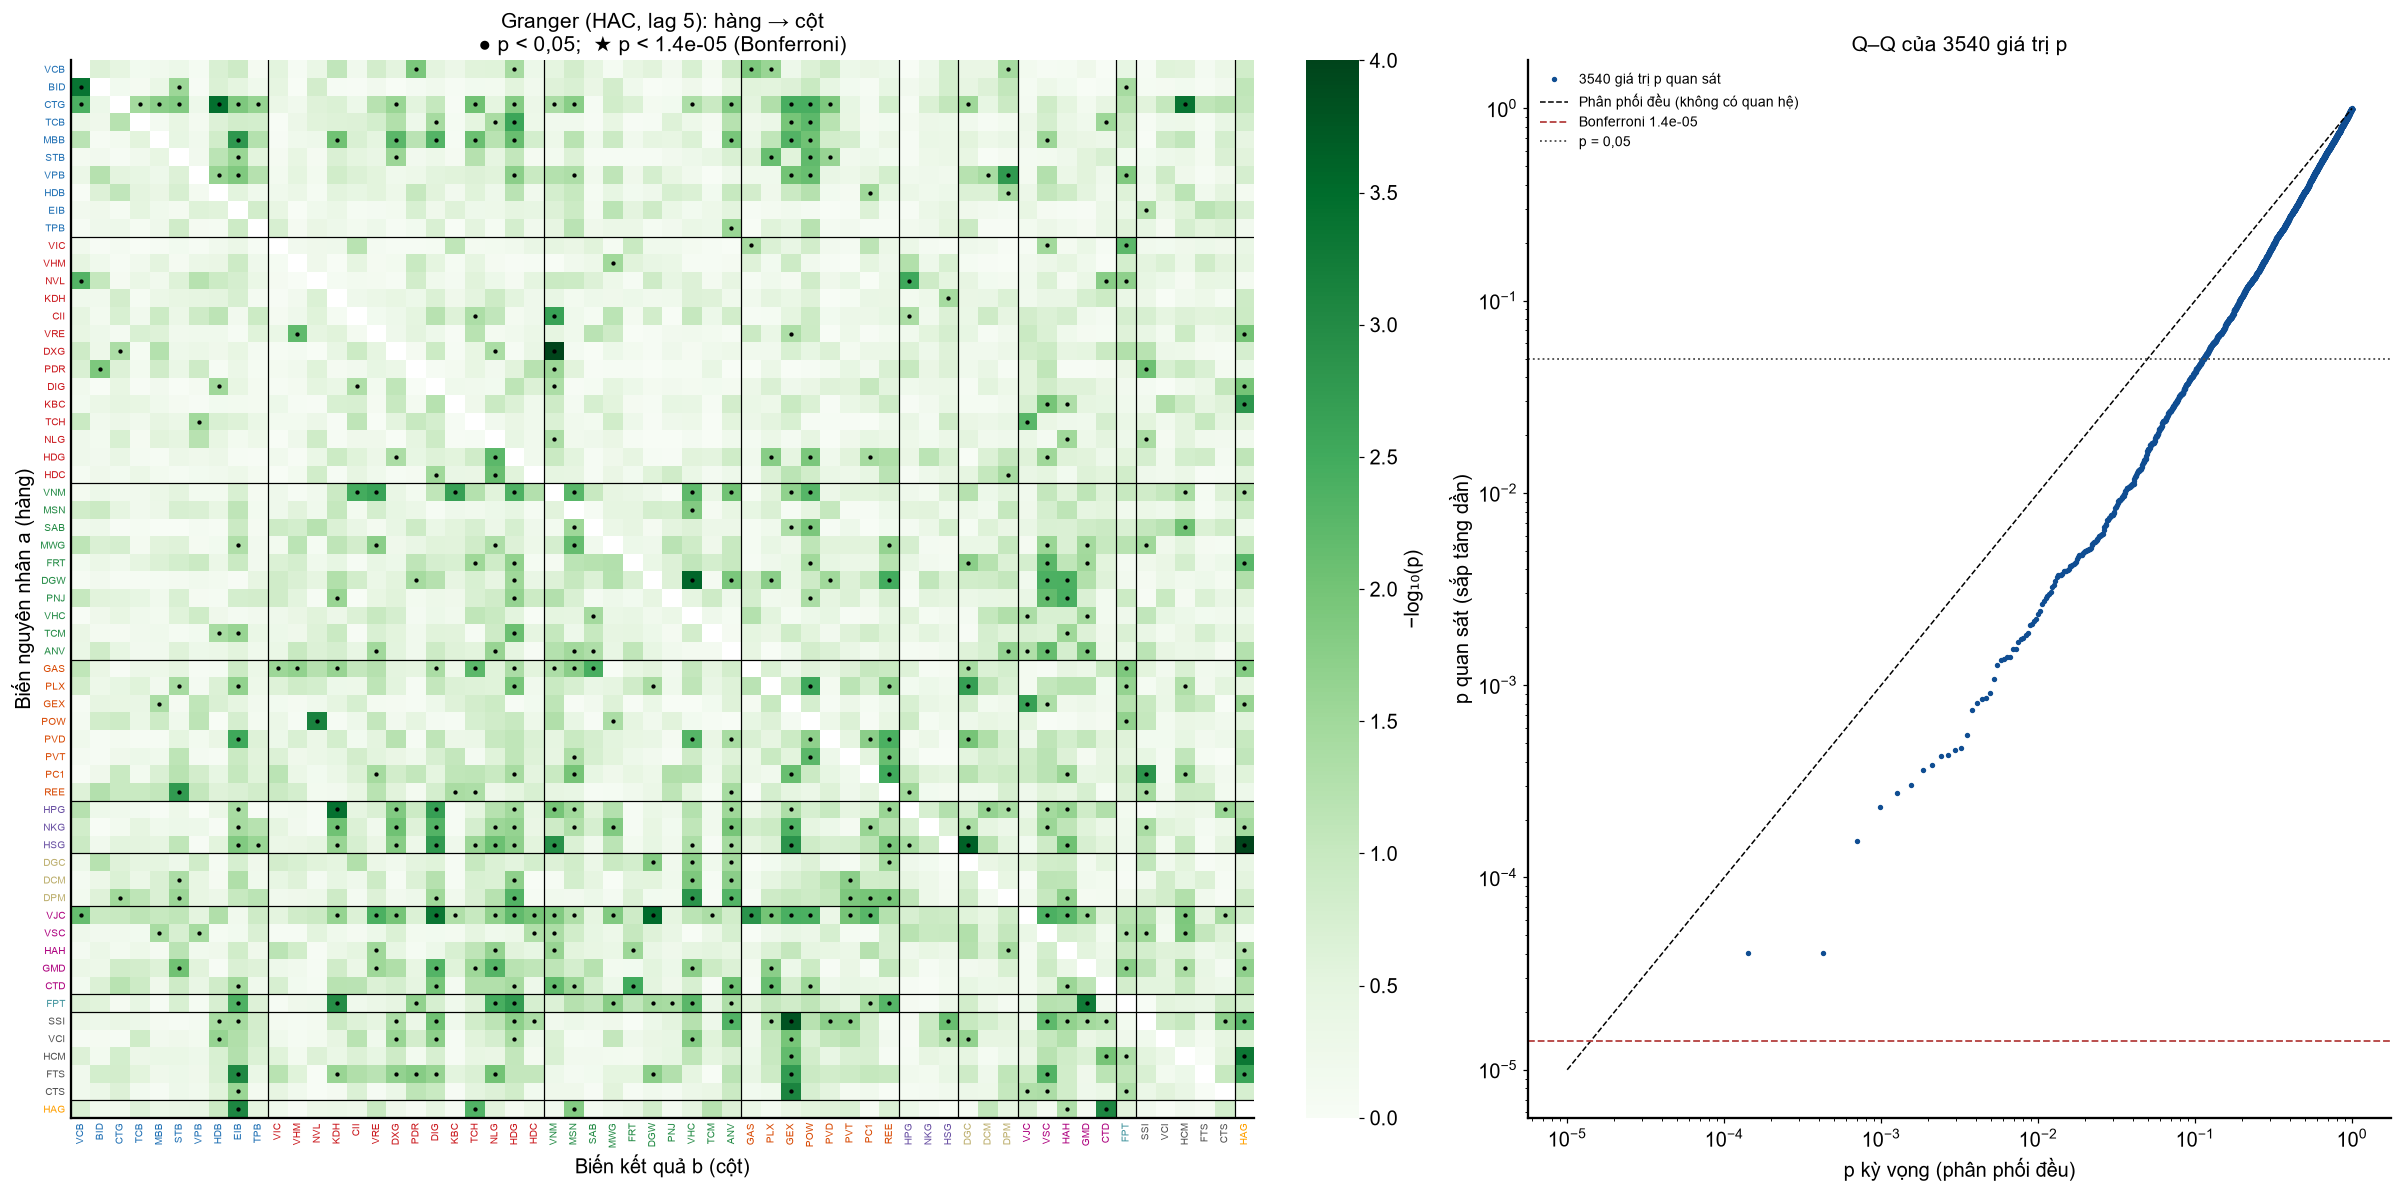

3540 kiểm định | p < 0,05: 402 (11.4%; kỳ vọng ngẫu nhiên 5%) | Bonferroni: 0 | Holm: 0
Tỷ lệ p < 0,05: cùng ngành 0.100 | khác ngành 0.116
p nhỏ nhất: [['DXG→VNM', 4e-05, 0.14251], ['HSG→HAG', 4e-05, 0.1439], ['SSI→GEX', 0.00016, 0.55061], ['HSG→DGC', 0.00023, 0.82498], ['DGW→VHC', 0.00027, 0.96773]]


,Wald χ²(5),p (HAC),p Holm
cặp,,,
DXG→VNM,27.7760,0.0000,0.1425
HSG→HAG,27.7538,0.0000,0.1439
SSI→GEX,24.7511,0.0002,0.5506
HSG→DGC,23.8380,0.0002,0.8250
DGW→VHC,23.4760,0.0003,0.9677
VJC→DGW,23.2421,0.0003,1.0000
CTG→HDB,22.8433,0.0004,1.0000
HPG→KDH,22.6941,0.0004,1.0000


In [9]:
LAG = 5
lagged = {s: pd.concat({f"{s}_l{k}": r[s].shift(k) for k in range(1, LAG + 1)}, axis=1) for s in SYMBOLS}
rows = []
for a in SYMBOLS:
    for b in SYMBOLS:
        if a == b:
            continue
        X = sm.add_constant(pd.concat([lagged[b], lagged[a]], axis=1)).dropna()
        fit = sm.OLS(r[b].loc[X.index], X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        w = fit.wald_test(" = 0, ".join(lagged[a].columns) + " = 0", scalar=True)
        rows.append({"nguyên nhân": a, "kết quả": b, "cặp": f"{a}→{b}", "Wald χ²(5)": w.statistic, "p (HAC)": w.pvalue})
granger = pd.DataFrame(rows)
BONF = 0.05 / len(granger)
granger["p Holm"] = multipletests(granger["p (HAC)"], method="holm")[1]
granger["cùng ngành"] = [SECTOR[a] == SECTOR[b] for a, b in zip(granger["nguyên nhân"], granger["kết quả"])]
pmat = granger.pivot(index="nguyên nhân", columns="kết quả", values="p (HAC)").loc[SYMBOLS, SYMBOLS]

fig, axes = plt.subplots(1, 2, figsize=(22, 11), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
im = ax.imshow(-np.log10(pmat.values), cmap="Greens", vmin=0, vmax=4, aspect="auto")
for i in range(len(SYMBOLS)):
    for j in range(len(SYMBOLS)):
        p = pmat.values[i, j]
        if np.isnan(p): continue
        if p < BONF: ax.plot(j, i, marker="*", ms=8, color=PAL["red_strong"], mec="black", mew=0.4)
        elif p < 0.05: ax.plot(j, i, marker="o", ms=1.8, color="black")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("−log₁₀(p)"); cb.outline.set_visible(False)
ax.tick_params(length=0); sector_style(ax, SYMBOLS, fs=6.5)
ax.set_xlabel("Biến kết quả b (cột)"); ax.set_ylabel("Biến nguyên nhân a (hàng)")
ax.set_title(f"Granger (HAC, lag {LAG}): hàng → cột\n● p < 0,05;  ★ p < {BONF:.1e} (Bonferroni)")
p_sorted = np.sort(granger["p (HAC)"].values)
expected = (np.arange(1, len(p_sorted) + 1) - 0.5) / len(p_sorted)
axes[1].loglog(expected, p_sorted, "o", ms=2.5, color=PAL["blue_main"], label=f"{len(p_sorted)} giá trị p quan sát")
axes[1].plot([1e-5, 1], [1e-5, 1], color="black", ls="--", lw=1, label="Phân phối đều (không có quan hệ)")
axes[1].axhline(BONF, color=PAL["red_strong"], ls="--", lw=1.2, label=f"Bonferroni {BONF:.1e}")
axes[1].axhline(0.05, color=PAL["gray_dark"], ls=":", lw=1.2, label="p = 0,05")
axes[1].set_xlabel("p kỳ vọng (phân phối đều)"); axes[1].set_ylabel("p quan sát (sắp tăng dần)")
axes[1].set_title(f"Q–Q của {len(p_sorted)} giá trị p"); axes[1].legend(fontsize=9, loc="upper left")
U.finalize_figure(fig, "finding_8_granger"); plt.show()
n05 = int((granger["p (HAC)"] < 0.05).sum())
print(f"{len(granger)} kiểm định | p < 0,05: {n05} ({n05/len(granger):.1%}; kỳ vọng ngẫu nhiên 5%) | Bonferroni: {int((granger['p (HAC)'] < BONF).sum())} | Holm: {int((granger['p Holm'] < 0.05).sum())}")
print("Tỷ lệ p < 0,05: cùng ngành %.3f | khác ngành %.3f" % tuple(granger.groupby("cùng ngành")["p (HAC)"].apply(lambda p: (p < .05).mean()).reindex([True, False])))
print("p nhỏ nhất:", granger.sort_values("p (HAC)").head(5)[["cặp", "p (HAC)", "p Holm"]].round(5).values.tolist())
granger.sort_values("p (HAC)").set_index("cặp")[["Wald χ²(5)", "p (HAC)", "p Holm"]].head(8)

### Phân tích

- **Không cặp nào** vượt ngưỡng Bonferroni ($p < 1{,}4\times10^{-5}$) hay Holm trong 3.540 kiểm định. Nhỏ nhất: DXG→VNM và HSG→HAG (p = 4·10⁻⁵; Holm 0,14), SSI→GEX, HSG→DGC, DGW→VHC (≈ 2–3·10⁻⁴).
- **402/3.540 cặp (11,4%) có $p < 0{,}05$**, gấp 2,3 lần kỳ vọng ngẫu nhiên (177 cặp); Q–Q lệch về phía $p$ nhỏ trong vùng 10⁻³–10⁻¹ → có **quan hệ dẫn–trễ yếu rải rác**, không cặp nào đủ mạnh.
  Tỷ lệ $p < 0{,}05$ gần như bằng nhau cùng ngành (10,0%) và khác ngành (11,6%).
- Hệ quả: ở tần suất ngày, quan hệ giữa các mã chủ yếu là **đồng thời** — phương pháp nhân quả cần khai thác cấu trúc đồng thời (đuôi dày) thay vì độ trễ.

## Phát hiện 9 — Khối lượng giao dịch tăng thì biến động tăng

**Tính gì:** quan hệ giữa khối lượng tương đối và độ lớn lợi suất trong cùng phiên.

**Công thức.**

- Khối lượng tương đối: $RV_{i,t} = V_{i,t} \Big/ \frac{1}{20}\sum_{k=1}^{20} V_{i,t-k}$ — khối lượng hôm nay so với trung bình 20 phiên **trước đó**
  ($RV > 1$: giao dịch sôi động bất thường). Cột `rel_volume` trong CSDL.
- Tương quan hạng Spearman giữa $\ln RV_{i,t}$ và $|r_{i,t}|$: $\rho_S = 1 - \dfrac{6\sum_t d_t^2}{T(T^2-1)}$, $d_t$ là chênh lệch hạng —
  đo quan hệ đơn điệu, không đòi hỏi tuyến tính và ít nhạy với giá trị ngoại lai.
- Trung bình theo nhóm thập phân vị (decile): chia các phiên thành 10 nhóm bằng nhau theo $\ln RV$, tính $\overline{|r|}$ trong từng nhóm.

**Các bước:** (1) lấy `rel_volume` và `log_ret` trong khung phân tích; (2) tính $\rho_S$ cho từng mã;
(3) tính $\overline{|r|}$ theo decile của $\ln RV$ và vẽ đường cho từng mã.

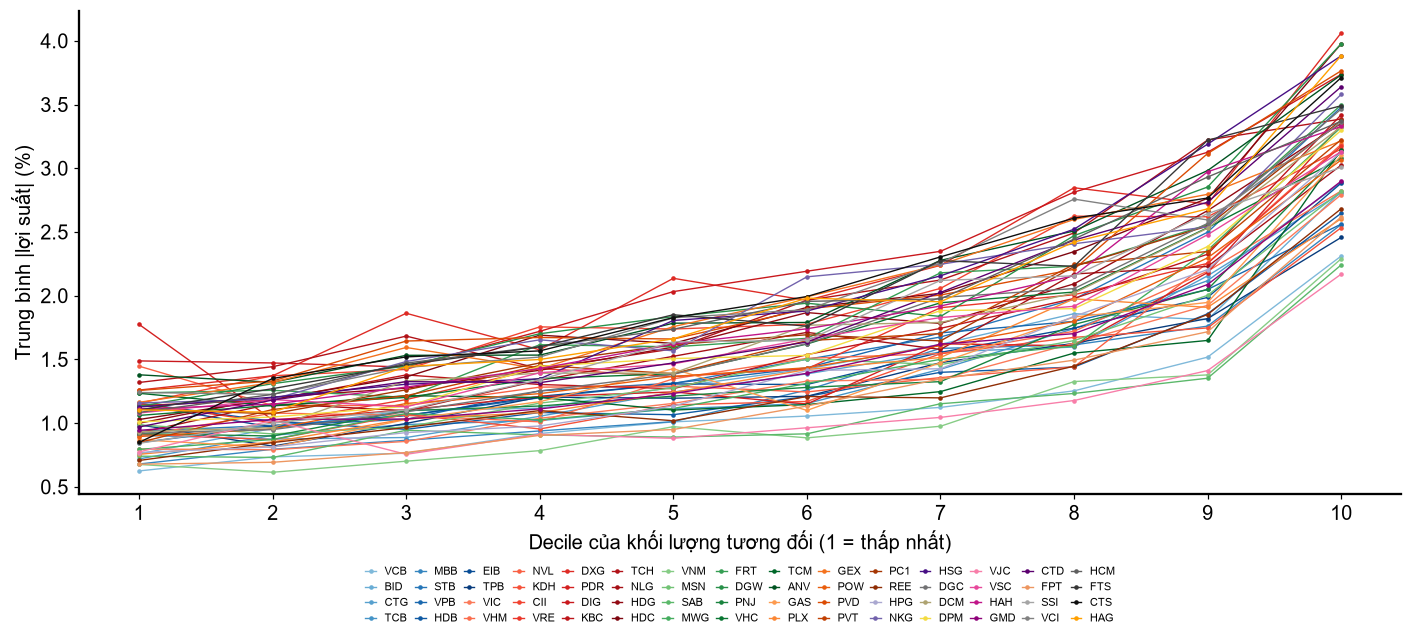

Spearman ρ_S: min 0.19 (TCM) | max 0.44 (HPG) | TB 0.34 | p < 0,001: 60 | tỷ số D10/D1: min 1.9 | max 4.4


,ngành,Spearman ρ_S,p-value,|r| decile 1 (%),|r| decile 10 (%),tỷ số D10/D1
symbol,,,,,,
VCB,Ngân hàng,0.3157,0.0000,0.6247,2.3111,3.6996
BID,Ngân hàng,0.3429,0.0000,0.7585,2.8172,3.7144
CTG,Ngân hàng,0.3431,0.0000,0.9036,2.8061,3.1056
TCB,Ngân hàng,0.3878,0.0000,0.7192,2.8890,4.0172
MBB,Ngân hàng,0.3681,0.0000,0.6791,2.5585,3.7677
STB,Ngân hàng,0.4068,0.0000,0.9367,3.4798,3.7148
VPB,Ngân hàng,0.3111,0.0000,0.8462,2.5613,3.0267
HDB,Ngân hàng,0.2524,0.0000,1.1562,2.6467,2.2892
EIB,Ngân hàng,0.2722,0.0000,1.1456,2.8830,2.5166


In [10]:
vv = con.execute("SELECT symbol, ABS(log_ret) AS abs_r, LN(rel_volume) AS ln_rv FROM v_analysis WHERE rel_volume > 0").df()
rows = []
fig, ax = plt.subplots(figsize=(13, 6))
for s in SYMBOLS:
    d = vv[vv.symbol == s].copy()
    d["decile"] = pd.qcut(d.ln_rv, 10, labels=range(1, 11))
    m = d.groupby("decile", observed=True).abs_r.mean()
    ax.plot(m.index.astype(int), 100 * m.values, marker="o", ms=2, lw=0.9, color=COL[s], label=s)
    rho = stats.spearmanr(d.ln_rv, d.abs_r)
    rows.append({"symbol": s, "ngành": SECTOR[s], "Spearman ρ_S": rho.statistic, "p-value": rho.pvalue,
                 "|r| decile 1 (%)": 100 * m.iloc[0], "|r| decile 10 (%)": 100 * m.iloc[-1], "tỷ số D10/D1": m.iloc[-1] / m.iloc[0]})
ax.set_xticks(range(1, 11)); ax.set_xlabel("Decile của khối lượng tương đối (1 = thấp nhất)")
ax.set_ylabel("Trung bình |lợi suất| (%)")
ax.legend(ncol=15, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.13), columnspacing=0.6, handlelength=1.0)
U.finalize_figure(fig, "finding_9_volume_volatility"); plt.show()
vv_tab = pd.DataFrame(rows).set_index("symbol")
print("Spearman ρ_S: min %.2f (%s) | max %.2f (%s) | TB %.2f | p < 0,001: %d | tỷ số D10/D1: min %.1f | max %.1f" % (
    vv_tab["Spearman ρ_S"].min(), vv_tab["Spearman ρ_S"].idxmin(), vv_tab["Spearman ρ_S"].max(), vv_tab["Spearman ρ_S"].idxmax(),
    vv_tab["Spearman ρ_S"].mean(), (vv_tab["p-value"] < 1e-3).sum(), vv_tab["tỷ số D10/D1"].min(), vv_tab["tỷ số D10/D1"].max()))
vv_tab

### Phân tích

- Ở cả 60 mã, $|r|$ trung bình tăng theo decile khối lượng tương đối, từ decile thấp nhất đến cao nhất **1,9 lần (PDR) đến 4,4 lần (CTS)**; Spearman $\rho_S$ = 0,19–0,44 (trung bình 0,34), p < 0,001 ở 60/60 mã;
  mạnh nhất HPG (0,44), MWG (0,43), STB, DGC (0,41); yếu nhất TCM (0,19), VJC (0,21), NVL (0,23).
- Quan hệ **không đơn điệu** ở đầu thấp với một số mã (NVL, PDR: decile 1 có $|r|$ 1,4–1,8%) — phiên sàn/trần liên tiếp có khối lượng khớp thấp nhưng $|r|$ lớn.
- Hệ quả: khối lượng mang thông tin về biến động cùng phiên (giả thuyết phân phối hỗn hợp); có thể đưa vào mô hình biến động (GARCH-X).

## Phát hiện 10 — Khác biệt giữa các ngành và giữa 20 mã cũ với 40 mã bổ sung

**Tính gì:** so sánh 10 ngành (và 20 mã cũ với 40 mã bổ sung) về lợi suất, biến động, MDD, độ nhọn, mức bị chặn biên, hệ số tải PC1, tương quan và phụ thuộc đuôi dưới.

**Công thức.** Mọi chỉ số đã định nghĩa ở Phát hiện 2–7, ở đây lấy **trung bình theo nhóm**: $\bar x_G = \frac{1}{|G|}\sum_{i\in G}x_i$ cho chỉ số theo mã ($\mu$, $\sigma$, MDD, $K$, tỷ lệ phiên chạm trần/sàn, hệ số tải PC1);
$\bar\rho_G = \frac{1}{|P_G|}\sum_{(i,j)\in P_G}\rho_{ij}$ và $\bar\lambda_{L,G}$ tương tự cho chỉ số theo cặp, trong đó $P_G$ là tập các cặp có cả hai mã thuộc nhóm $G$ (ngành có 1 mã không có cặp nên để trống).

**Các bước:** (1) gom bảng theo ngành và theo nhóm cũ/bổ sung; (2) tính trung bình cặp trong ngành, trong nhóm và chéo giữa hai nhóm; (3) vẽ cột biến động và |MDD| theo ngành, cùng heatmap $\bar\lambda_L$ giữa từng cặp ngành.
**Lưu ý:** công nghệ (FPT) và nông nghiệp (HAG) chỉ có 1 mã, thép và hoá chất 3 mã — số liệu trung bình ngành chỉ mang tính mô tả.

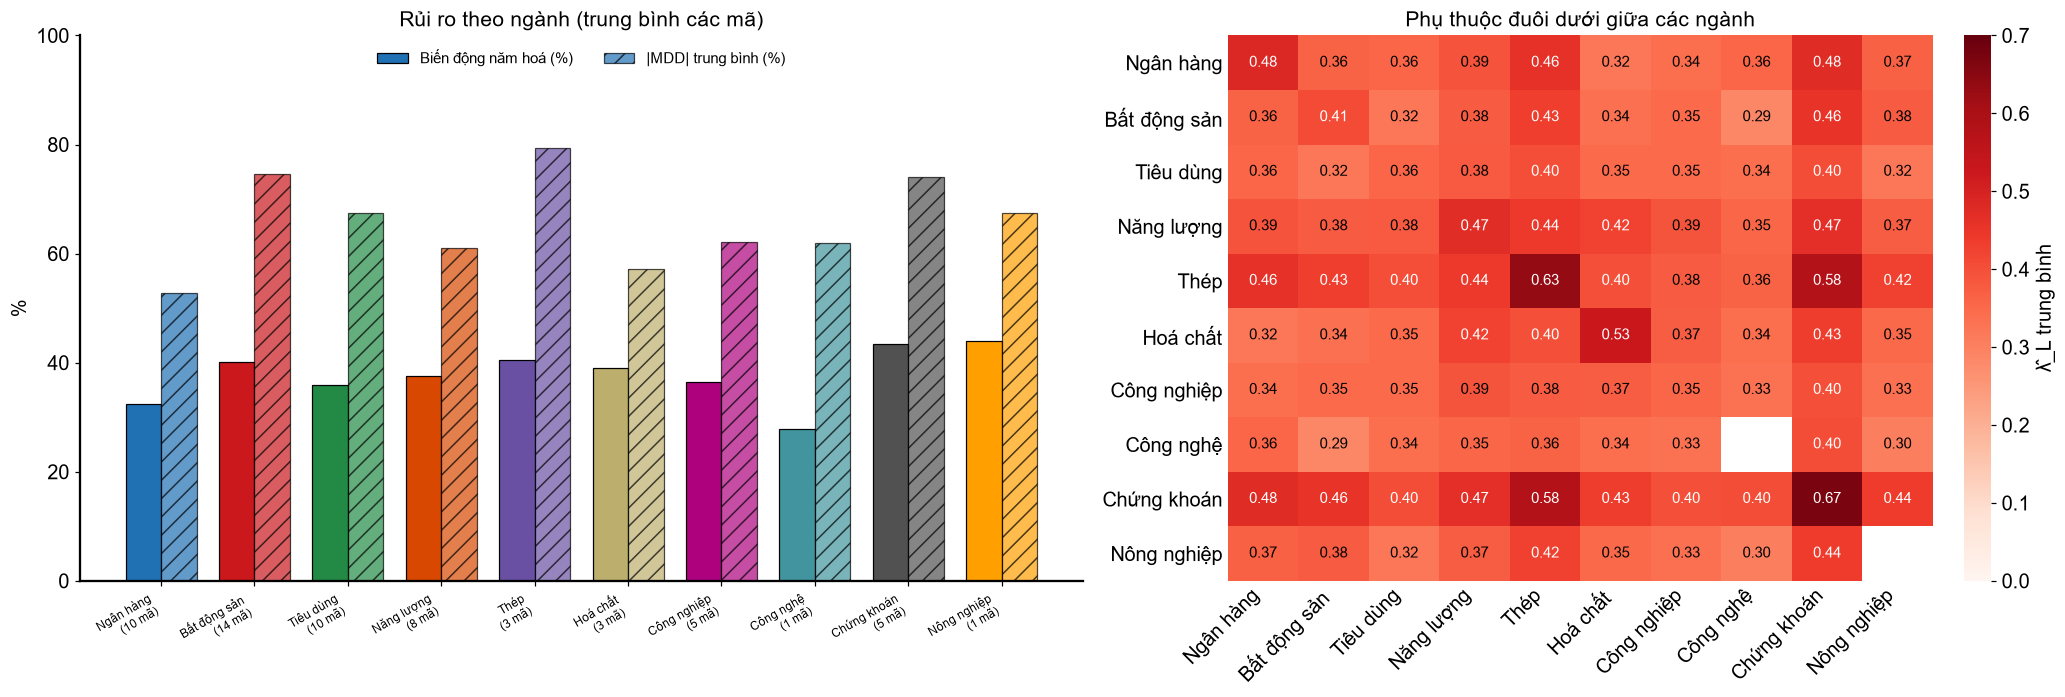

,số mã,mu_nam (%),sigma_nam (%),MDD TB (%),K TB,% phiên chạm biên,PC1 TB,ρ trong ngành,λ̂_L trong ngành
ngành,,,,,,,,,
Ngân hàng,10,12.8050,32.5070,-52.7500,2.4510,2.1790,0.1350,0.5130,0.4810
Bất động sản,14,4.5690,40.1250,-74.6100,1.5260,5.0980,0.1250,0.4070,0.4060
Tiêu dùng,10,7.3910,35.9390,-67.4000,2.1260,3.7550,0.1150,0.3320,0.3570
Năng lượng,8,8.5040,37.5200,-60.9480,1.7910,3.9050,0.1290,0.4440,0.4710
Thép,3,9.0220,40.5150,-79.4290,1.2560,5.1730,0.1450,0.7150,0.6340
Hoá chất,3,19.5180,39.0980,-57.0980,1.5680,4.2180,0.1160,0.5550,0.5260
Công nghiệp,5,13.5950,36.4930,-62.1730,1.9780,3.4620,0.1120,0.3260,0.3550
Công nghệ,1,16.1300,27.7970,-61.8870,2.8700,1.0380,0.1370,NaN,NaN
Chứng khoán,5,16.3680,43.4430,-74.1110,1.0180,6.4530,0.1550,0.6990,0.6700


,số mã,mu_nam (%),sigma_nam (%),MDD TB (%),K TB,% phiên chạm biên,PC1 TB,ρ trong nhóm,λ̂_L trong nhóm
nhóm,,,,,,,,,
20 cũ,20.0000,8.1340,32.5280,-59.4980,2.5360,2.3140,0.1270,0.3830,0.3670
40 bổ sung,40.0000,10.9530,40.1530,-69.1000,1.4500,5.0420,0.1270,0.3610,0.4130
chéo (cũ–bổ sung),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3420,0.3670


In [11]:
GROUP = {s: ("20 cũ" if s in BASE else "40 bổ sung") for s in SYMBOLS}
kurt = shape["K (độ nhọn vượt chuẩn)"]
box = (hits.ty_le_tran + hits.ty_le_san)                       # tỷ lệ phiên chạm trần hoặc sàn
base = pd.DataFrame({"ngành": [SECTOR[s] for s in SYMBOLS], "nhóm": [GROUP[s] for s in SYMBOLS],
                     "mu_nam": summary.mu_nam, "sigma_nam": summary.sigma_nam, "MDD": summary.MDD,
                     "K": kurt, "chạm biên": box, "PC1": loadings["PC1"]}, index=SYMBOLS)
corr_s = pd.Series(R.values[iu], index=pair_names)
def grp_pairs(mask_fn):
    return np.array([mask_fn(a, b) for a, b in pairs])
rows = []
for sec in SECTORS:
    m = [s for s in SYMBOLS if SECTOR[s] == sec]
    inside = grp_pairs(lambda a, b: SECTOR[a] == sec and SECTOR[b] == sec)
    rows.append({"ngành": sec, "số mã": len(m), "mu_nam (%)": 100 * base.loc[m, "mu_nam"].mean(),
                 "sigma_nam (%)": 100 * base.loc[m, "sigma_nam"].mean(), "MDD TB (%)": 100 * base.loc[m, "MDD"].mean(),
                 "K TB": base.loc[m, "K"].mean(), "% phiên chạm biên": 100 * base.loc[m, "chạm biên"].mean(),
                 "PC1 TB": base.loc[m, "PC1"].mean(),
                 "ρ trong ngành": corr_s[inside].mean() if inside.any() else np.nan,
                 "λ̂_L trong ngành": tail["λ̂_L"][inside].mean() if inside.any() else np.nan})
by_sector = pd.DataFrame(rows).set_index("ngành")
U.save_table(by_sector, "finding_10_by_sector", folder="eda")

rows = []
for g in ("20 cũ", "40 bổ sung"):
    m = [s for s in SYMBOLS if GROUP[s] == g]
    inside = grp_pairs(lambda a, b: GROUP[a] == g and GROUP[b] == g)
    rows.append({"nhóm": g, "số mã": len(m), "mu_nam (%)": 100 * base.loc[m, "mu_nam"].mean(),
                 "sigma_nam (%)": 100 * base.loc[m, "sigma_nam"].mean(), "MDD TB (%)": 100 * base.loc[m, "MDD"].mean(),
                 "K TB": base.loc[m, "K"].mean(), "% phiên chạm biên": 100 * base.loc[m, "chạm biên"].mean(),
                 "PC1 TB": base.loc[m, "PC1"].mean(), "ρ trong nhóm": corr_s[inside].mean(), "λ̂_L trong nhóm": tail["λ̂_L"][inside].mean()})
cross = grp_pairs(lambda a, b: GROUP[a] != GROUP[b])
by_group = pd.DataFrame(rows).set_index("nhóm")
by_group.loc["chéo (cũ–bổ sung)", ["ρ trong nhóm", "λ̂_L trong nhóm"]] = [corr_s[cross].mean(), tail["λ̂_L"][cross].mean()]
U.save_table(by_group, "finding_10_by_group", folder="eda")

# λ̂_L trung bình giữa các cặp ngành
lam_sec = pd.DataFrame(np.nan, index=SECTORS, columns=SECTORS)
for sa in SECTORS:
    for sb in SECTORS:
        ma, mb = [s for s in SYMBOLS if SECTOR[s] == sa], [s for s in SYMBOLS if SECTOR[s] == sb]
        blk = lamL.loc[ma, mb].values
        v = blk[~np.isnan(blk)]
        if v.size: lam_sec.loc[sa, sb] = v.mean()

fig, axes = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
xx = np.arange(len(SECTORS)); wd = 0.38
axes[0].bar(xx - wd / 2, 100 * by_sector["sigma_nam (%)"] / 100, wd, color=[SC[s] for s in SECTORS], edgecolor="black", lw=0.8, label="Biến động năm hoá (%)")
axes[0].bar(xx + wd / 2, -by_sector["MDD TB (%)"], wd, color=[SC[s] for s in SECTORS], edgecolor="black", lw=0.8, hatch="//", alpha=0.7, label="|MDD| trung bình (%)")
axes[0].set_xticks(xx, [f"{s}\n({int(by_sector.loc[s, 'số mã'])} mã)" for s in SECTORS], fontsize=8, rotation=30, ha="right")
axes[0].set_ylabel("%"); axes[0].set_title("Rủi ro theo ngành (trung bình các mã)"); axes[0].set_ylim(0, 100); axes[0].legend(fontsize=10, loc="upper center", ncol=2)
U.make_heatmap(axes[1], lam_sec, cmap="Reds", vmin=0, vmax=0.7, cbar_label="λ̂_L trung bình", title="Phụ thuộc đuôi dưới giữa các ngành")
axes[1].set_xticks(range(len(SECTORS)), SECTORS, rotation=45, ha="right")
U.finalize_figure(fig, "finding_10_sectors"); plt.show()
display(by_sector.round(3)); by_group.round(3)

### Phân tích

**Theo ngành** (trung bình các mã; ngành 1–3 mã chỉ mang tính mô tả):

- **Rủi ro:** biến động cao nhất ở nông nghiệp (44,0%), chứng khoán (43,4%), thép (40,5%), bất động sản (40,1%); thấp nhất công nghệ (27,8%) và ngân hàng (32,5%). MDD trung bình nặng nhất ở **thép (−79,4%)**, bất động sản (−74,6%), chứng khoán (−74,1%); nhẹ nhất ngân hàng (−52,8%).
- **Lợi suất:** hoá chất +19,5%/năm, chứng khoán +16,4%, công nghệ +16,1%, công nghiệp +13,6%, ngân hàng +12,8%; thấp nhất bất động sản +4,6% và tiêu dùng +7,4%.
- **Mức bị chặn biên** (trần + sàn): nông nghiệp 7,2%, chứng khoán 6,5%, thép 5,2%, bất động sản 5,1%; thấp nhất công nghệ 1,0% và ngân hàng 2,2% → độ tin cậy của phân tích đuôi khác nhau theo ngành.
- **Gắn kết:** ngành gắn kết nhất là **thép (ρ 0,72; $\bar\lambda_L$ 0,63)** và **chứng khoán (0,70; 0,67)**, rồi hoá chất (0,56; 0,53), ngân hàng (0,51; 0,48); yếu nhất công nghiệp (0,33; 0,36) và tiêu dùng (0,33; 0,36).
  Giữa các ngành, cao nhất thép–chứng khoán ($\bar\lambda_L$ 0,58), ngân hàng–chứng khoán (0,48), năng lượng–chứng khoán (0,47); thấp nhất bất động sản–công nghệ (0,29). Chứng khoán có tải PC1 lớn nhất (0,155).

**20 mã cũ so với 40 mã bổ sung:**

- Nhóm bổ sung **biến động hơn (40,2% so với 32,5%), MDD sâu hơn (−69,1% so với −59,5%), bị chặn biên gấp đôi (5,0% so với 2,3% số phiên)**, độ nhọn thấp hơn (K = 1,45 so với 2,54); lợi suất trung bình cao hơn (11,0% so với 8,1%/năm).
- Hệ số tải PC1 trung bình **bằng nhau** (0,127) — 40 mã bổ sung chịu nhân tố thị trường như 20 mã cũ. Tương quan trong nhóm 0,38 (cũ) và 0,36 (bổ sung), chéo 0,34; nhưng $\bar\lambda_L$ trong nhóm bổ sung **cao hơn** (0,41 so với 0,37):
  mã nhỏ ít tương quan trong phiên thường nhưng cùng sập mạnh hơn — một phần do cùng chạm sàn (ties tại biên).
- Các phát hiện chính của giai đoạn 20 mã (đuôi dày, bị chặn ±7%, biến động cụm, nhân tố thị trường, phụ thuộc đuôi vượt Gaussian, Granger không có ý nghĩa sau hiệu chỉnh, khối lượng–biến động) **đều giữ nguyên** trên 60 mã;
  điều thay đổi là (i) chặn biên nặng hơn nhiều, (ii) cấu trúc ngành hẹp rõ hơn, (iii) nhân tố thị trường chiếm tỷ trọng nhỏ hơn.

## Tổng kết — từ phát hiện đến lựa chọn mô hình

### Phân tích

| # | Phát hiện | Bằng chứng chính (60 mã) | Hệ quả cho bước mô hình hoá |
|---|---|---|---|
| 1 | VHM trước 17/05/2018 là giá ảo; TCB niêm yết 04/06/2018 | 629 phiên giá đứng; lợi suất ảo +268% | Khung chung 01/06/2018 → 25/11/2026 (T = 2.103 phiên chung) |
| 2 | Lợi suất khác biệt lớn | HAH +32,3%, DGW +25,7%; NVL −11,6% (MDD −91,2%), PNJ −10,5%; σ 24–49% | Xử lý NVL, PNJ thận trọng khi diễn giải |
| 3 | Không chuẩn, đuôi dày | K = 0,45–4,28; JB p < 0,001 (60/60); 4,9–12,5% phiên đứng giá | Bỏ giả định chuẩn; cẩn trọng với khối xác suất tại 0 |
| 4 | Đuôi bị chặn ±7% | 3.048 phiên sát biên; trần + sàn 0,6% (VNM) – 9,2% (DIG); 54/60 mã có ≥ 14 phiên mỗi biên | EVT có kiểm duyệt hoặc phương pháp dựa trên hạng sau lọc GARCH |
| 5 | Biến động cụm | $\hat\rho_{|r|}(1)$ = 0,13–0,37; Q(10) của $r^2$: p ≈ 0 (60/60); đỉnh chung 68% (07/12/2022) | Lọc GARCH / sai số HAC trước phân tích phụ thuộc |
| 6 | Nhân tố thị trường + nhân tố ngành hẹp | PC1 37,5%; PC2–PC4 mỗi cái 3–4% (hoá chất, phòng thủ, Vingroup); ρ trong ngành thép 0,72, chứng khoán 0,70 | Khử nhân tố thị trường **và** xét riêng các ngành hẹp |
| 7 | Phụ thuộc đuôi dưới > Gaussian | $\hat\lambda_L$ 0,39 so với $\lambda_G$ 0,16; 1.770/1.770 cặp dương, CI > 0 ở 1.746 | Phương pháp nhân quả cho đuôi dày |
| 8 | Không có dẫn–trễ vượt hiệu chỉnh | 402/3.540 cặp p < 0,05 (kỳ vọng 177), 0 cặp qua Bonferroni/Holm | Tập trung vào quan hệ đồng thời |
| 9 | Khối lượng ↔ biến động | $\rho_S$ = 0,19–0,44 (60/60 có p < 0,001); decile cao gấp 1,9–4,4 lần | Khối lượng là biến giải thích cho biến động |
| 10 | Khác biệt ngành; 20 cũ so với 40 bổ sung | Gắn kết cao nhất: thép, chứng khoán; nhóm bổ sung σ 40,2% / chặn biên 5,0% so với 32,5% / 2,3% | Diễn giải theo ngành; xử lý chặn biên nặng ở mã nhỏ |

**Thứ tự đề xuất cho bước tiếp theo:** (1) lọc GARCH-t cho từng mã → phần dư chuẩn hoá; (2) lưu ý các quan sát trần/sàn (ở phần lớn mã, toàn bộ đuôi là phiên chạm biên);
(3) mô hình hoá phụ thuộc đồng thời và phụ thuộc đuôi trên phần dư, có kiểm soát nhân tố thị trường và nhân tố ngành.